## 서울시 서초구, 양천구 주차시설 확보를 위한 데이터 분석 프로젝트
### 프로젝트 개요
본 프로젝트는 서울시 서초구와 양천구의 공영주차장 정보 및 불법 주정차 단속 현황 데이터를 분석하여, 각 지역의 주차 문제를 파악하고 주차 공간 공급과 불법 주정차 발생 간의 연관성을 시각적으로 탐색합니다. 최종적으로 데이터 분석 결과를 바탕으로 주차 문제 해결을 위한 아이디어를 제안하는 것을 목표로 합니다.

In [1]:
# 데이터 분석 및 시각화를 위한 라이브러리들을 임포트합니다.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import warnings
from datetime import datetime
import os
import glob
import matplotlib.font_manager as fm
import subprocess

# 폰트 설정
plt.rc('font', family='Malgun Gothic')

# 경고 제거
import warnings
warnings.filterwarnings(action='ignore')

In [94]:
import pandas as pd
seocho_crackdown = pd.read_csv("서울특별시 서초구_주정차단속 시간별 현황_20241231.csv", encoding = "cp949")
seocho_parking_lot = pd.read_csv("서울시 서초구 공영주차장 안내 정보.csv", encoding = "cp949")

In [91]:
yangcheon_crackdown1 = pd.read_csv("서울특별시 양천구_주정차위반단속현황_20231220.csv", encoding = "cp949")
yangcheon_crackdown2 = pd.read_csv("서울특별시 양천구_주정차위반단속현황_20221231.csv", encoding = "cp949")
yangcheon_parking_lot = pd.read_csv("서울시 양천구 공영주차장 안내 정보.csv", encoding = "cp949")


In [112]:
seocho_crackdown['단속일시'] = pd.to_datetime(seocho_crackdown['단속일시'], errors='coerce')
seocho_crackdown = seocho_crackdown[seocho_crackdown['단속일시'].dt.year != 2024] #24년 제거
seocho_crackdown.dropna(subset=['단속일시'], inplace=True)
seocho_crackdown['단속시간'] = seocho_crackdown['단속일시'].dt.hour
seocho_crackdown['단속동'] = (seocho_crackdown['단속동'].str.extract(r'([가-힣]+)\d*동', expand=False).add('동'))
seocho_parking_lot['주소_동'] = seocho_parking_lot['주소'].str.split().str[1]

In [92]:
yangcheon_crackdown = pd.concat([yangcheon_crackdown1, yangcheon_crackdown2], ignore_index=True)

yangcheon_crackdown['단속일시'] = pd.to_datetime(yangcheon_crackdown['단속일시'], errors='coerce')
yangcheon_crackdown.dropna(subset=['단속일시'], inplace=True)
yangcheon_crackdown['단속시간'] = yangcheon_crackdown['단속일시'].dt.hour
yangcheon_crackdown['단속동'] = yangcheon_crackdown['단속동'].str.replace(' ', '')
yangcheon_crackdown['단속동'] = (yangcheon_crackdown['단속동'].str.extract(r'([가-힣]+)\d*동', expand=False).add('동'))
yangcheon_crackdown = yangcheon_crackdown[yangcheon_crackdown['단속동'].str.contains('동', na=False)]
yangcheon_parking_lot['주소_동'] = yangcheon_parking_lot['주소'].str.split().str[1]

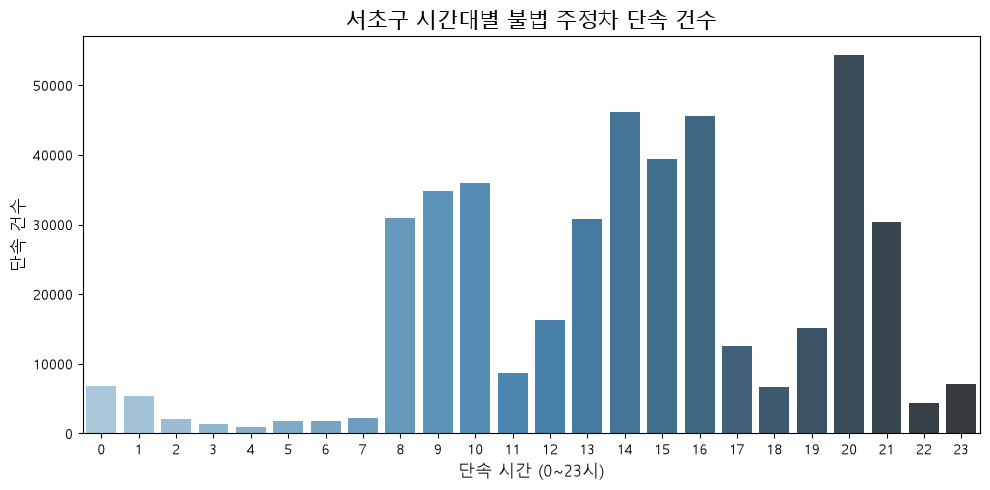

In [120]:
plt.figure(figsize=(10, 5))

# 시간대별 단속 건수 계산 후 시간 순서대로 정렬
seocho_hourly = seocho_crackdown['단속시간'].value_counts().sort_index()

# 시각화 (막대그래프)
sns.barplot(x=seocho_hourly.index, y=seocho_hourly.values, palette='Blues_d')
plt.title('서초구 시간대별 불법 주정차 단속 건수', fontsize=15)
plt.xlabel('단속 시간 (0~23시)', fontsize=12)
plt.ylabel('단속 건수', fontsize=12)

plt.tight_layout()
plt.show()

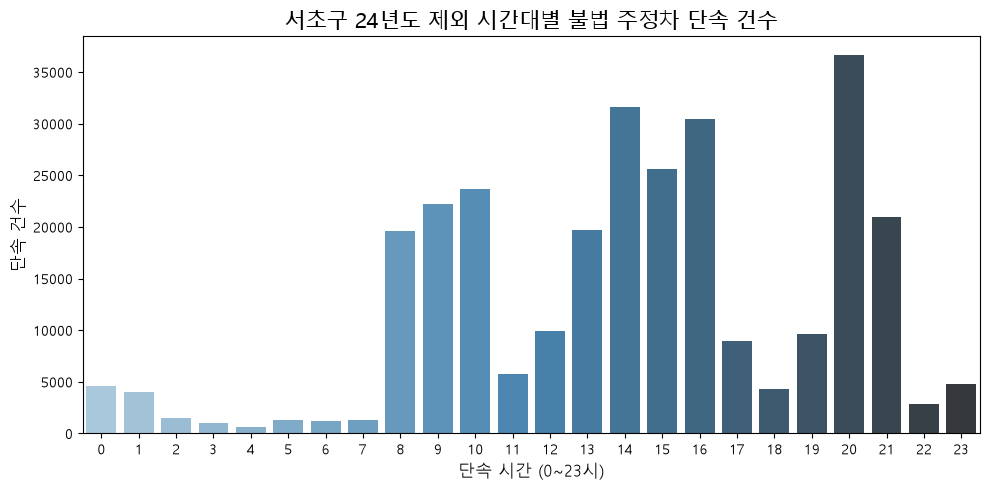

In [8]:
plt.figure(figsize=(10, 5))

seocho_hourly = seocho_crackdown['단속시간'].value_counts().sort_index()

sns.barplot(x=seocho_hourly.index, y=seocho_hourly.values, palette='Blues_d')
plt.title('서초구 24년도 제외 시간대별 불법 주정차 단속 건수', fontsize=15)
plt.xlabel('단속 시간 (0~23시)', fontsize=12)
plt.ylabel('단속 건수', fontsize=12)

plt.tight_layout()
plt.show()

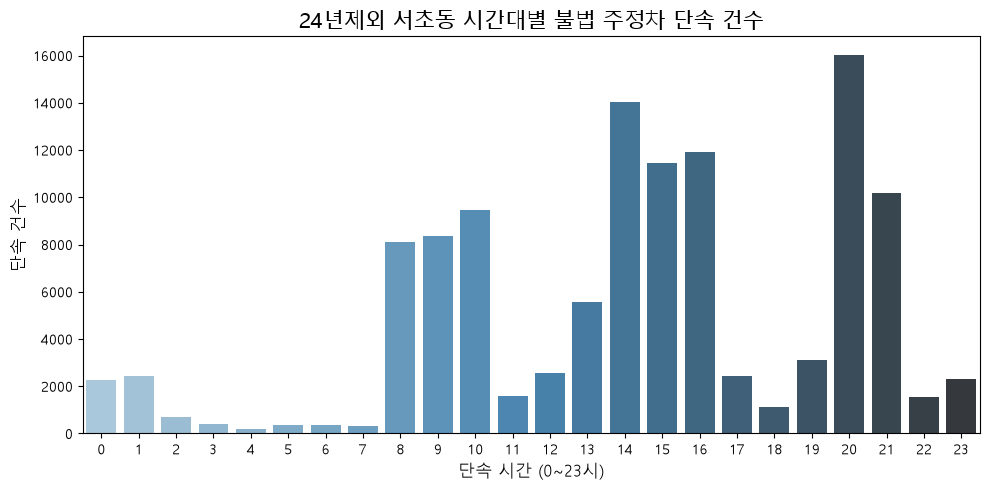

In [98]:
plt.figure(figsize=(10, 5))

seocho_dong_data = seocho_crackdown[seocho_crackdown['단속동'] == '서초동']

seocho_dong_hourly = seocho_dong_data['단속시간'].value_counts().sort_index()

sns.barplot(x=seocho_dong_hourly.index, y=seocho_dong_hourly.values, palette='Blues_d')
plt.title('24년제외 서초동 시간대별 불법 주정차 단속 건수', fontsize=15)
plt.xlabel('단속 시간 (0~23시)', fontsize=12)
plt.ylabel('단속 건수', fontsize=12)
plt.tight_layout()
plt.show()

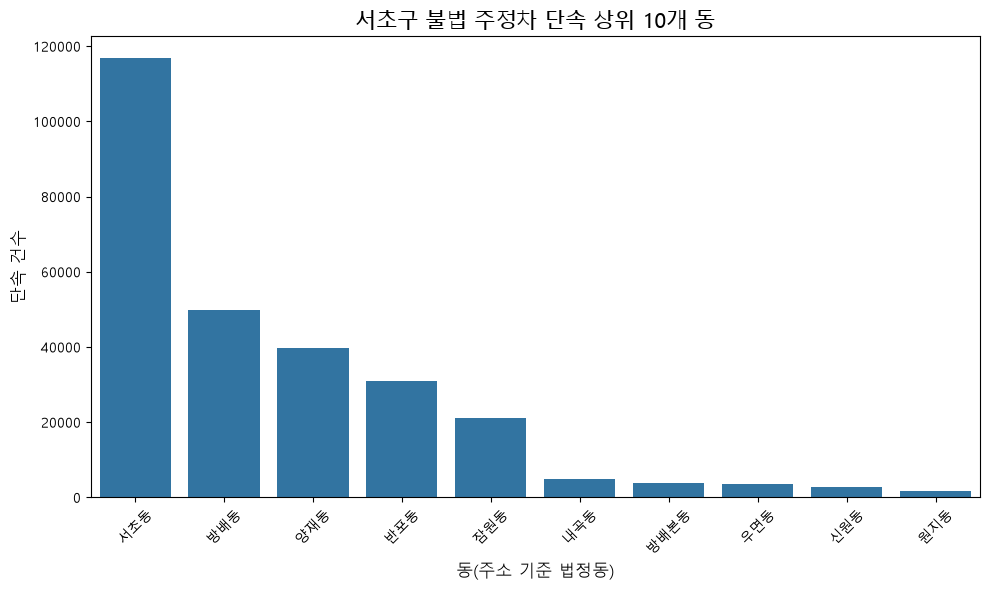

In [21]:
# --- 지역별 주정차 단속 현황 비교 ---
plt.figure(figsize=(10,6))

# 서초구 단속 현황
# '단속동'별로 단속 건수를 세고, 가장 많은 상위 10개 동을 추출합니다.
seocho_top_dong = seocho_crackdown['단속동'].value_counts().nlargest(10)

sns.barplot(x=seocho_top_dong.index, y=seocho_top_dong.values)
plt.title('서초구 불법 주정차 단속 상위 10개 동', fontsize=15) # 그래프 제목 설정
plt.xlabel('동(주소 기준 법정동)', fontsize=12) # x축 라벨 설정
plt.ylabel('단속 건수',fontsize=12) # y축 라벨 설정
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

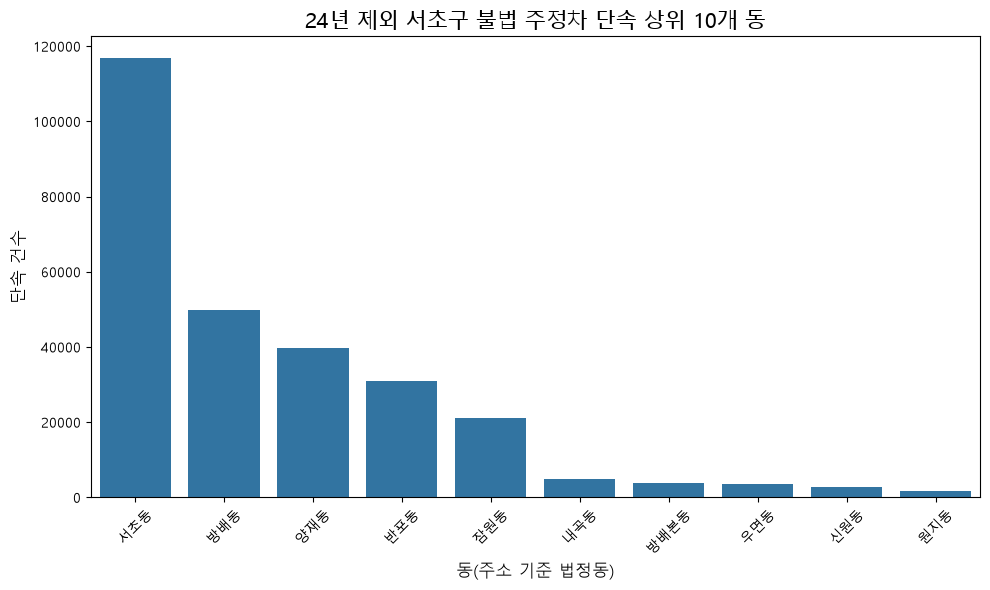

In [24]:
# --- 지역별 주정차 단속 현황 비교 ---
plt.figure(figsize=(10,6))

# 서초구 단속 현황
# '단속동'별로 단속 건수를 세고, 가장 많은 상위 10개 동을 추출합니다.
seocho_top_dong = seocho_crackdown['단속동'].value_counts().nlargest(10)

sns.barplot(x=seocho_top_dong.index, y=seocho_top_dong.values)
plt.title('24년 제외 서초구 불법 주정차 단속 상위 10개 동', fontsize=15) # 그래프 제목 설정
plt.xlabel('동(주소 기준 법정동)', fontsize=12) # x축 라벨 설정
plt.ylabel('단속 건수',fontsize=12) # y축 라벨 설정
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

--- 서초동 불법 주정차 단속 상위 장소 Top 10 ---
단속장소
N05018 강남I-PARK애비뉴 주변             4754
N07011 삼미빌딩 주변                    3930
N05012 설국일식 주변                    2898
N10001 블루핀타워 주변                   2749
서울특별시 서초구 서초대로78길 56 (서초동, 금성상    2393
N05010 남촌빌딩 주변                    2341
P12010 가마솥영양족발                    2325
N05006 서초우성5차 501동 주변             2285
N05009 법원로중앙법원입구2                 2269
N11005 서초아트자이102동주변               2205
Name: count, dtype: int64


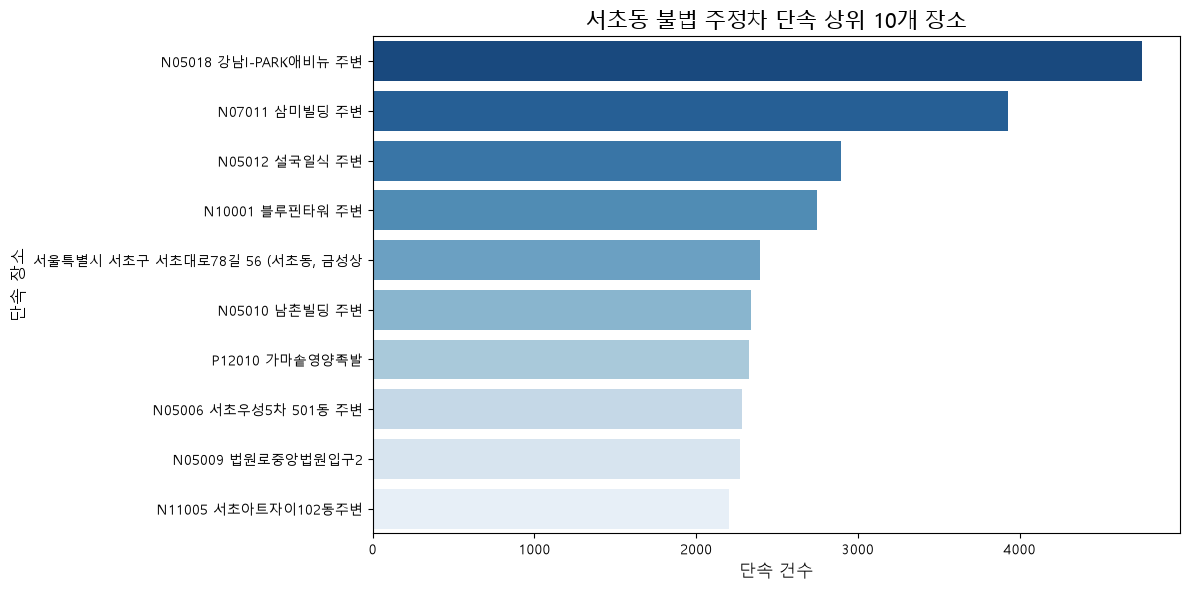

In [184]:
seocho_dong_data = seocho_crackdown[seocho_crackdown['단속동'] == '서초동']

top_locations = seocho_dong_data['단속장소'].value_counts().nlargest(10)

print("--- 서초동 불법 주정차 단속 상위 장소 Top 10 ---")
print(top_locations)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_locations.values, y=top_locations.index, palette='Blues_r')
plt.title('서초동 불법 주정차 단속 상위 10개 장소', fontsize=15)
plt.xlabel('단속 건수', fontsize=12)
plt.ylabel('단속 장소', fontsize=12)
plt.tight_layout()
plt.show()

---서초동 불법 주정차 단속 상위 장소 Top 10 ---
단속장소
N05018 강남I-PARK애비뉴 주변             3364
N07011 삼미빌딩 주변                    2687
N05012 설국일식 주변                    2566
서울특별시 서초구 서초대로78길 56 (서초동, 금성상    1911
N10001 블루핀타워 주변                   1777
N05009 법원로중앙법원입구2                 1599
P12010 가마솥영양족발                    1502
N11005 서초아트자이102동주변               1476
N10003 서초역1번출구주변                  1446
N05010 남촌빌딩 주변                    1411
Name: count, dtype: int64


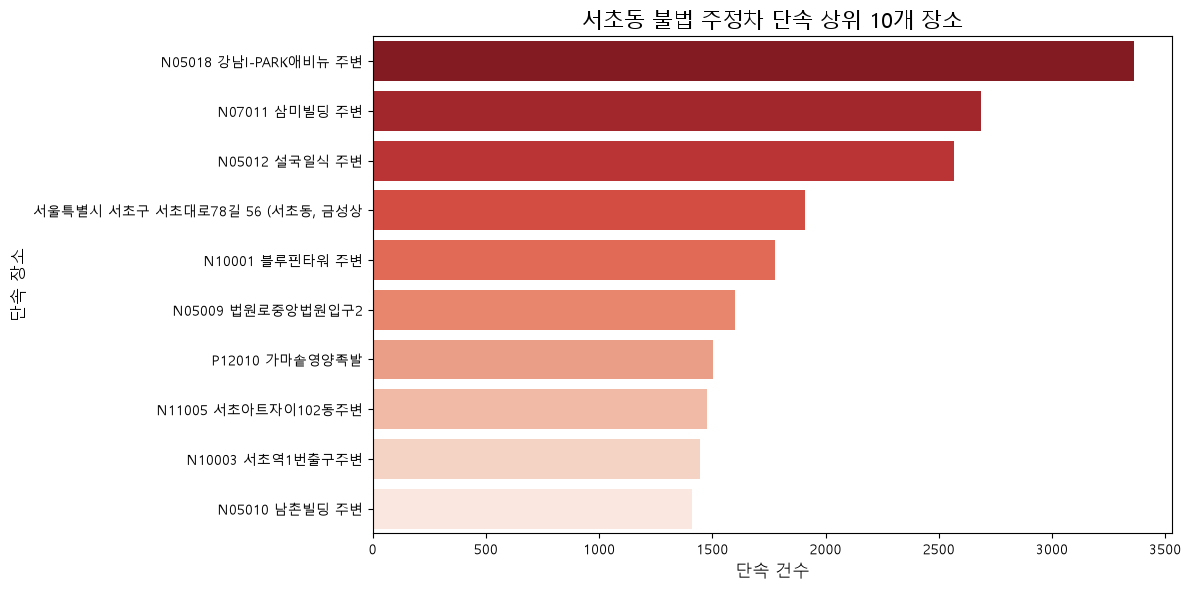

In [115]:
seocho_dong_data = seocho_crackdown[seocho_crackdown['단속동'] == '서초동']

top_locations = seocho_dong_data['단속장소'].value_counts().nlargest(10)

print("---서초동 불법 주정차 단속 상위 장소 Top 10 ---")
print(top_locations)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_locations.values, y=top_locations.index, palette='Reds_r')
plt.title('서초동 불법 주정차 단속 상위 10개 장소', fontsize=15)
plt.xlabel('단속 건수', fontsize=12)
plt.ylabel('단속 장소', fontsize=12)
plt.tight_layout()
plt.show()

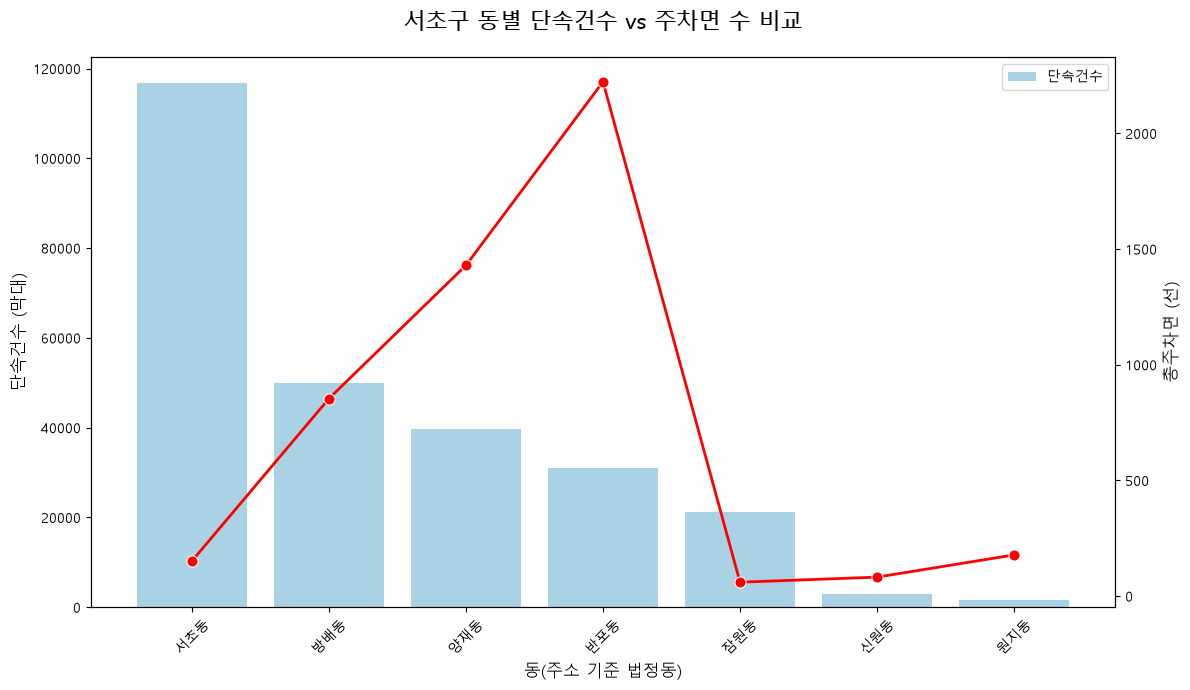

In [34]:
seocho_crackdown_counts = seocho_top_dong.reset_index()
seocho_crackdown_counts.columns = ['주소_동', '단속건수']

seocho_parking_supply = seocho_parking_lot.groupby('주소_동')['총 주차면'].sum().sort_values(ascending=False)
seocho_parking_supply_df = seocho_parking_supply.reset_index()
seocho_parking_supply_df.columns = ['주소_동', '총주차면']

seocho_merged = pd.merge(seocho_crackdown_counts, seocho_parking_supply_df, on='주소_동', how='inner')

# 2. 이중 축 시각화
plt.figure(figsize=(12, 7))
ax1 = plt.gca()

# 단속건수 (막대그래프)
sns.barplot(x='주소_동', y='단속건수', data=seocho_merged, ax=ax1, color='skyblue', label='단속건수', alpha=0.8)

# 총주차면 (꺾은선그래프)
ax2 = ax1.twinx()
sns.lineplot(x='주소_동', y='총주차면', data=seocho_merged, ax=ax2, color='red', marker='o', markersize=8, linewidth=2, sort=False)

# 레이블 및 타이틀 설정
ax1.set_title('서초구 동별 단속건수 vs 주차면 수 비교', fontsize=16, pad=20)
ax1.set_xlabel('동(주소 기준 법정동)', fontsize=12)
ax1.set_ylabel('단속건수 (막대)', fontsize=12)
ax2.set_ylabel('총주차면 (선)', fontsize=12)
ax1.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

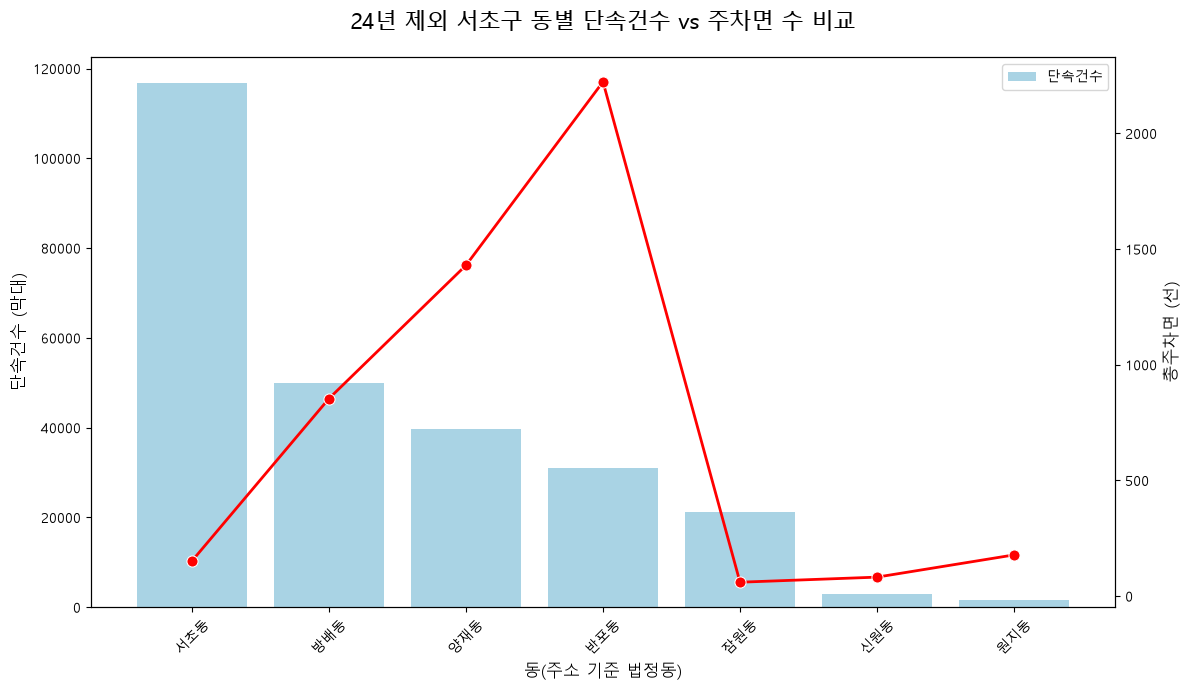

In [28]:
seocho_crackdown_counts = seocho_top_dong.reset_index()
seocho_crackdown_counts.columns = ['주소_동', '단속건수']

seocho_parking_supply = seocho_parking_lot.groupby('주소_동')['총 주차면'].sum().sort_values(ascending=False)
seocho_parking_supply_df = seocho_parking_supply.reset_index()
seocho_parking_supply_df.columns = ['주소_동', '총주차면']

seocho_merged = pd.merge(seocho_crackdown_counts, seocho_parking_supply_df, on='주소_동', how='inner')

plt.figure(figsize=(12, 7))
ax1 = plt.gca()

sns.barplot(x='주소_동', y='단속건수', data=seocho_merged, ax=ax1, color='skyblue', label='단속건수', alpha=0.8)

ax2 = ax1.twinx()
sns.lineplot(x='주소_동', y='총주차면', data=seocho_merged, ax=ax2, color='red', marker='o', markersize=8, linewidth=2, sort=False)

ax1.set_title('24년 제외 서초구 동별 단속건수 vs 주차면 수 비교', fontsize=16, pad=20)
ax1.set_xlabel('동(주소 기준 법정동)', fontsize=12)
ax1.set_ylabel('단속건수 (막대)', fontsize=12)
ax2.set_ylabel('총주차면 (선)', fontsize=12)
ax1.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

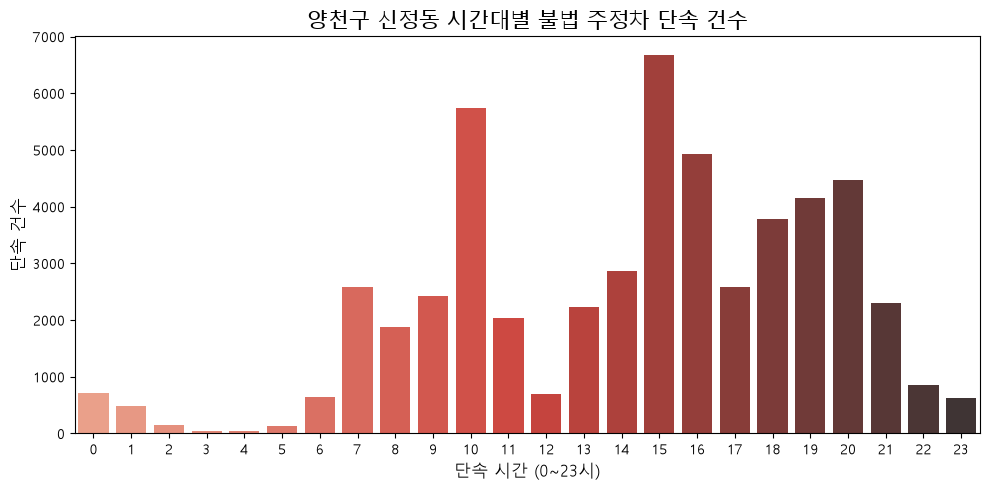

In [45]:
plt.figure(figsize=(10, 5))

# 1. '목동' 지역만 필터링한 후 시간대별 단속 건수 계산 및 정렬
# (※ 주의: 데이터프레임의 동 이름 열 이름이 '단속동'이 아닐 경우 실제 열 이름으로 변경해 주세요!)
mokdong_data = yangcheon_crackdown[yangcheon_crackdown['단속동'] == '신정동']
mokdong_hourly = mokdong_data['단속시간'].value_counts().sort_index()

# 2. 시각화 (막대그래프)
sns.barplot(x=mokdong_hourly.index, y=mokdong_hourly.values, palette='Reds_d')
plt.title('양천구 신정동 시간대별 불법 주정차 단속 건수', fontsize=15)
plt.xlabel('단속 시간 (0~23시)', fontsize=12)
plt.ylabel('단속 건수', fontsize=12)

plt.tight_layout()
plt.show()

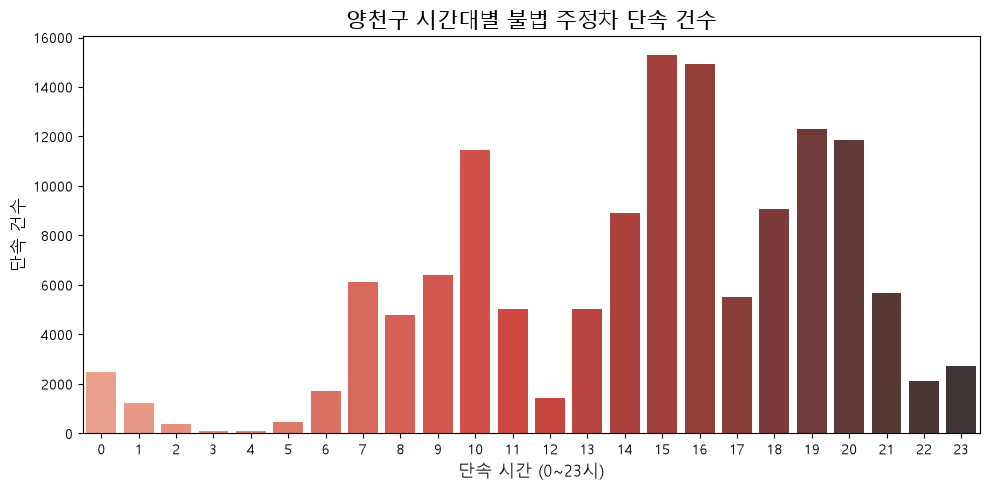

In [122]:
plt.figure(figsize=(10, 5))

# 시간대별 단속 건수 계산 후 시간 순서대로 정렬
yangcheon_hourly = yangcheon_crackdown['단속시간'].value_counts().sort_index()

# 시각화 (막대그래프)
sns.barplot(x=yangcheon_hourly.index, y=yangcheon_hourly.values, palette='Reds_d')
plt.title('양천구 시간대별 불법 주정차 단속 건수', fontsize=15)
plt.xlabel('단속 시간 (0~23시)', fontsize=12)
plt.ylabel('단속 건수', fontsize=12)

plt.tight_layout()
plt.show()

--- 양천구 신정동 불법 주정차 단속 상위 장소 Top 10 ---
단속장소
신정3동 서남병원 후문              1937
으뜸어린이집 주변                 1117
금석궁 근처 사거리 주변             1046
목동힐스테이트103동 주변            1002
목동유치원 주변                   990
양천구청역 2번출구앞 삼거리            948
신정6동 서울강림교회 주변             938
서울 양천구 중앙로34길 12 (신정동)     845
양동초교 주변                    750
래미안목동아델리체                  746
Name: count, dtype: int64


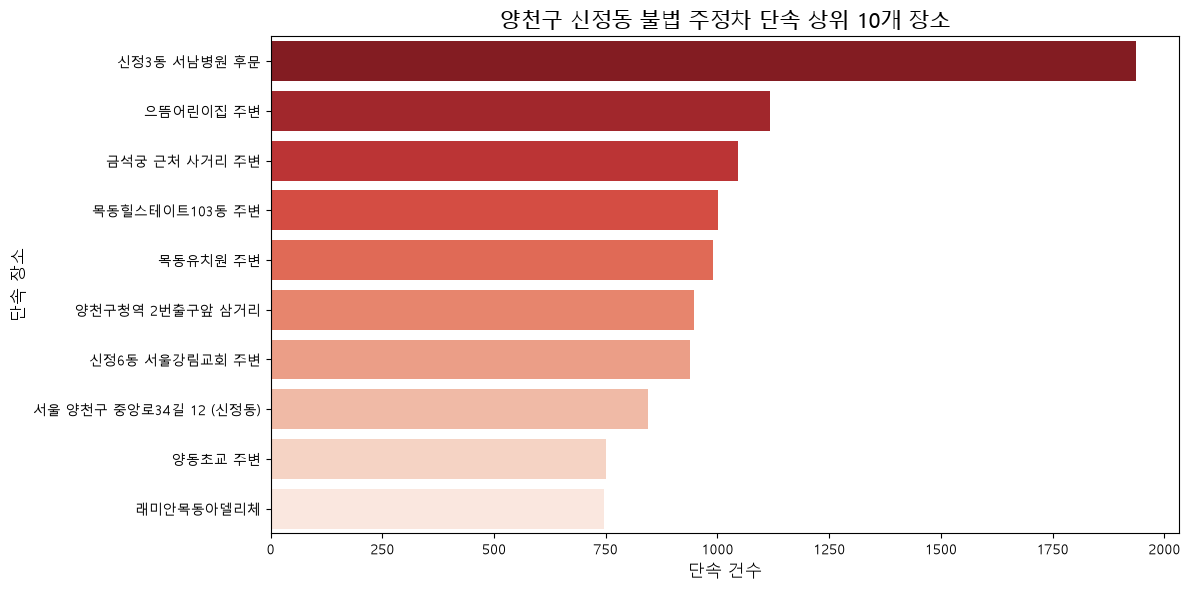

In [93]:
# --- 양천구 전체 데이터 중 '신정동'만 필터링 ---
shinjung_crackdown = yangcheon_crackdown[
    yangcheon_crackdown['단속동'] == '신정동'
]

# 신정동 내에서 단속장소 상위 10개 추출
top_shinjung_locations = (
    shinjung_crackdown['단속장소'].value_counts().nlargest(10)
)

print('--- 양천구 신정동 불법 주정차 단속 상위 장소 Top 10 ---')
print(top_shinjung_locations)

# 2. 시각화 (수평 막대그래프)
plt.figure(figsize=(12, 6))
sns.barplot(
    x=top_shinjung_locations.values,
    y=top_shinjung_locations.index,
    palette='Reds_r',
)
plt.title('양천구 신정동 불법 주정차 단속 상위 10개 장소', fontsize=15)
plt.xlabel('단속 건수', fontsize=12)
plt.ylabel('단속 장소', fontsize=12)
plt.tight_layout()
plt.show()

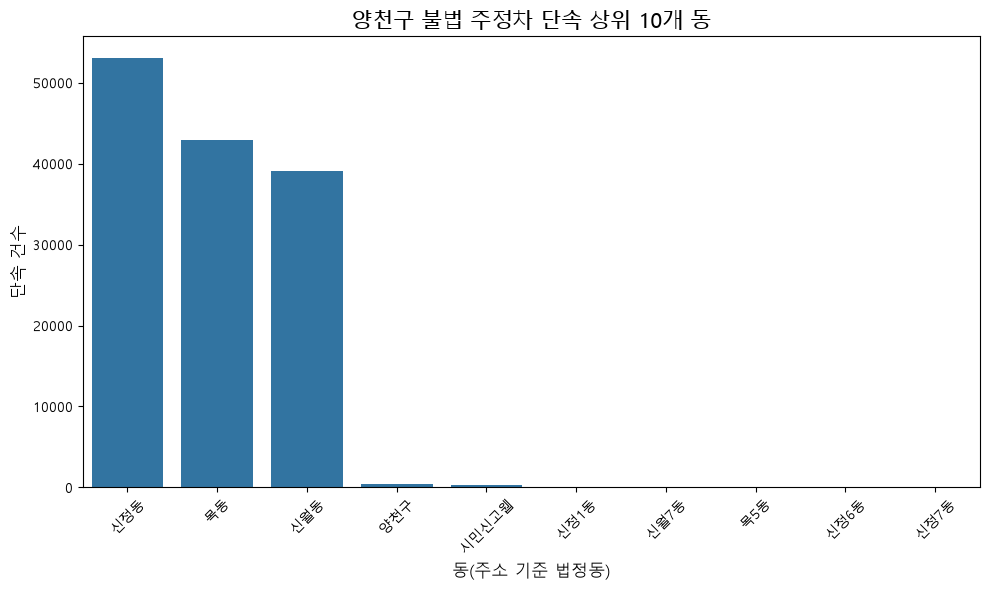

In [170]:
plt.figure(figsize=(10,6))
yangcheon_top_dong = yangcheon_crackdown['단속동'].value_counts().nlargest(10)
sns.barplot(x=yangcheon_top_dong.index, y=yangcheon_top_dong.values)
plt.title('양천구 불법 주정차 단속 상위 10개 동', fontsize=15) 
plt.xlabel('동(주소 기준 법정동)', fontsize=12) 
plt.ylabel('단속 건수',fontsize=12) 
plt.xticks(rotation=45)


plt.tight_layout()
plt.show()

#신정1동-4건, 신월7동-3건, 목5동-2건, 신정6동-2건 나머지 동등 데이터값 불충분으로 동별 통합, 법정동이 아닌 데이터값 제외

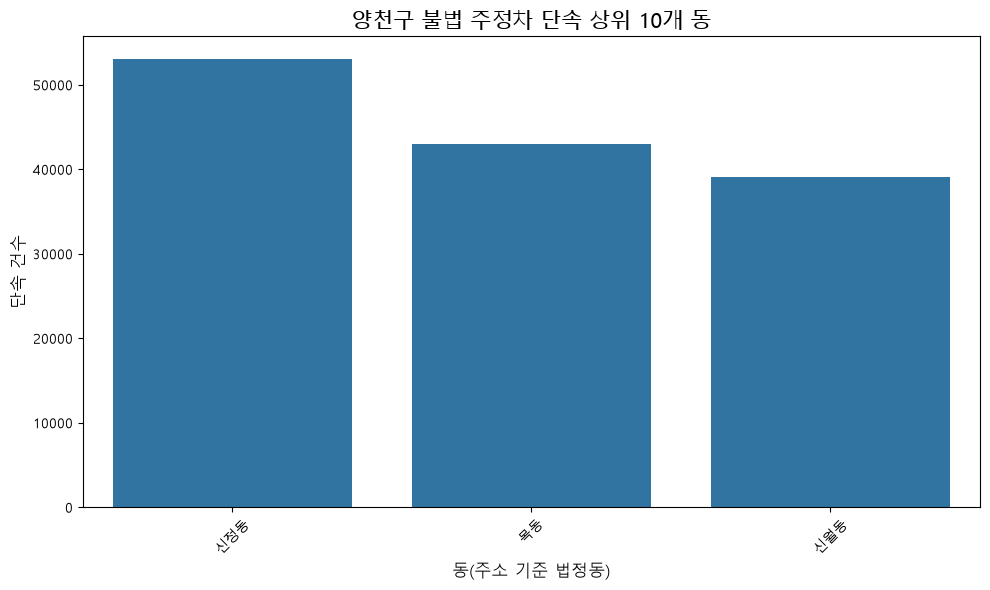

In [172]:
plt.figure(figsize=(10,6))
yangcheon_top_dong = yangcheon_crackdown['단속동'].value_counts().nlargest(10)
sns.barplot(x=yangcheon_top_dong.index, y=yangcheon_top_dong.values)
plt.title('양천구 불법 주정차 단속 상위 10개 동', fontsize=15) 
plt.xlabel('동(주소 기준 법정동)', fontsize=12) 
plt.ylabel('단속 건수',fontsize=12) 
plt.xticks(rotation=45)


plt.tight_layout()
plt.show()
#법정동 기준을 나누지 않고 행정동 기준으로 보아도 데이터가 의미있는 값으로 볼 수 없음으로 법정동 기준 통합진행

## 2.2. 지역별 공영주차장 공급 현황
각 지역의 행정동별 공영주차장 총 주차면 수를 계산하고 시각화하여 주차 공간 공급 현황을 비교합니다.

### **공급현황 비교**
지역별 공영주차장 공급 현황을 비교 해 봅니다.

**서초구 동별 주차면 수**
  - **'주소_동'** 을 기준으로 그룹화하여 **'총 주차면'** 의 합계를 계산하고, 내림차순으로 정렬합니다.
  - 동별 총 주차면 수를 막대그래프로 시각화합니다.

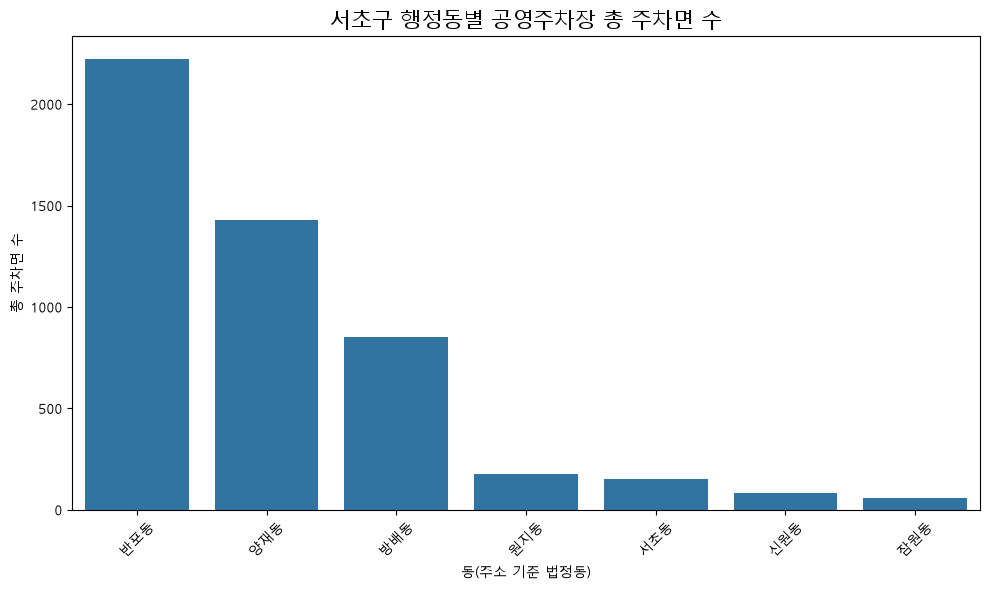

In [123]:
# 서초구 동별 주차면 수
# '주소_동'을 기준으로 그룹화하여 '총 주차면'의 합계를 계산하고, 내림차순으로 정렬합니다.
seocho_parking_supply = seocho_parking_lot.groupby('주소_동')['총 주차면'].sum().sort_values(ascending=False)

plt.figure(figsize=(10,6))

# 서초구 주차장 공급 현황
# 동별 총 주차면 수를 막대그래프로 시각화합니다.
sns.barplot(x=seocho_parking_supply.index, y=seocho_parking_supply.values)
plt.title('서초구 행정동별 공영주차장 총 주차면 수', fontsize=15)
plt.xlabel('동(주소 기준 법정동)')
plt.ylabel('총 주차면 수')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

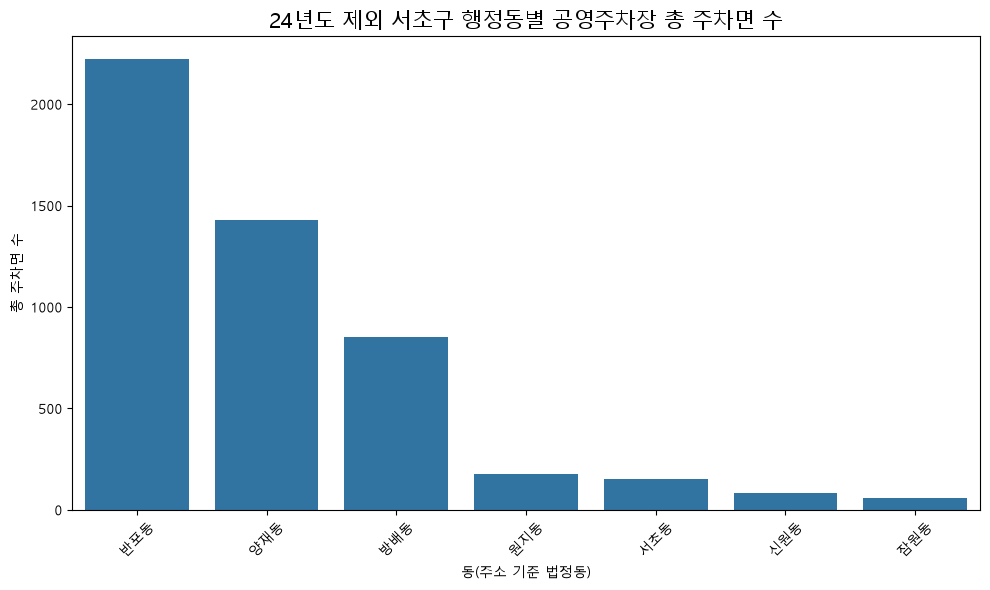

In [14]:

seocho_parking_supply1 = seocho_parking_lot.groupby('주소_동')['총 주차면'].sum().sort_values(ascending=False)

plt.figure(figsize=(10,6))


sns.barplot(x=seocho_parking_supply.index, y=seocho_parking_supply.values)
plt.title('24년도 제외 서초구 행정동별 공영주차장 총 주차면 수', fontsize=15)
plt.xlabel('동(주소 기준 법정동)')
plt.ylabel('총 주차면 수')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

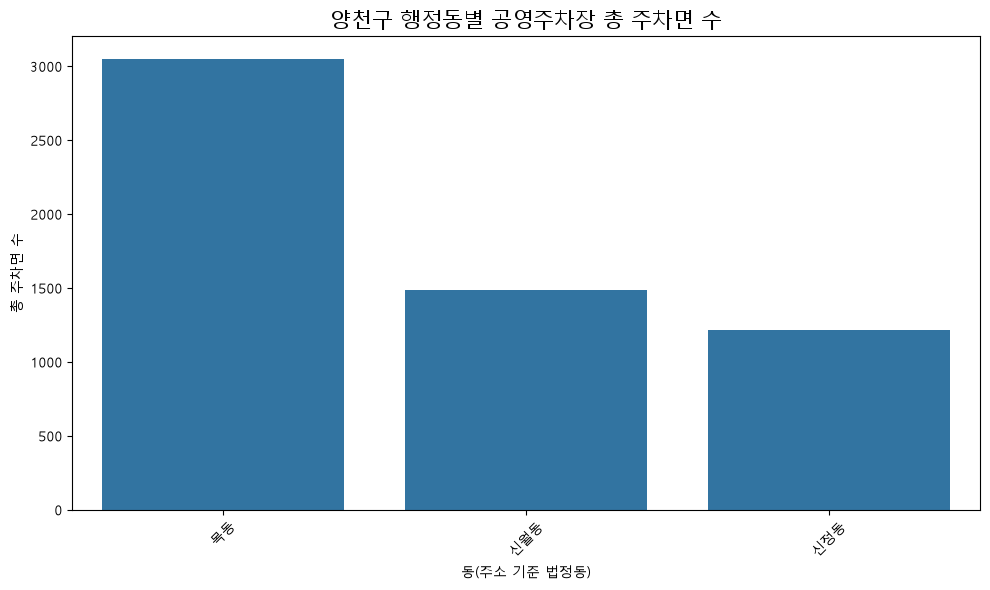

In [101]:
yangcheon_parking_supply = yangcheon_parking_lot.groupby('주소_동')['총 주차면'].sum().sort_values(ascending=False)

plt.figure(figsize=(10,6))

sns.barplot(x=yangcheon_parking_supply.index, y=yangcheon_parking_supply.values)
plt.title('양천구 행정동별 공영주차장 총 주차면 수', fontsize=15)
plt.xlabel('동(주소 기준 법정동)')
plt.ylabel('총 주차면 수')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 2.3. 주차장 공급과 불법 주정차의 연관 분석
주차 공간이 부족한 곳에서 불법 주정차가 많이 발생하는지 확인하기 위해, 동별 단속 건수와 총 주차면 수를 이중 축 그래프로 시각화하여 비교 분석합니다.

### **서초구 주차장 공급과 불법 주정차 위반과의 관계 살펴보기**

서초구 주차장 공급과 불법 주정차 단속 건수와의 관계를 확인해 봅니다.

**처리절차 예시**
  - 데이터 프레임으로 변환 : 분석을 위해 Series 형태의 데이터를 DataFrame으로 변환합니다.
  - 데이터 병합 : **'주소_동'** 을 기준으로 단속 건수 데이터와 주차면 수 데이터를 병합합니다.
  - 시각화 : 단속건수를 막대그래프로 그립니다. 총주차면을 꺾은선그래프로 그립니다.


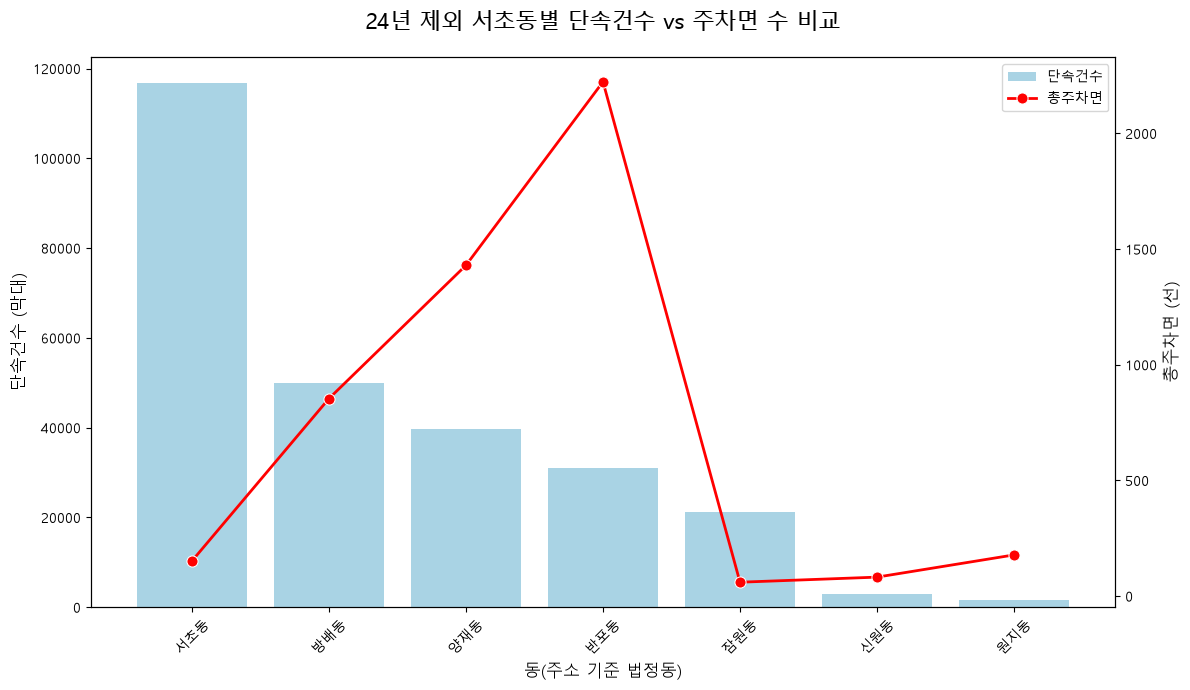

In [31]:
# --- 4. 연관 분석: 서초구 주차장 공급과 불법 주정차의 관계 ---

# 1. 데이터 프레임 변환 및 정제
# 서초구 단속 건수 데이터 변환
seocho_crackdown_counts = seocho_top_dong.reset_index()
seocho_crackdown_counts.columns = ['주소_동', '단속건수']

# 서초구 주차 공급 데이터 변환 (기존에 정의된 seocho_parking_supply 사용)
seocho_parking_supply_df = seocho_parking_supply.reset_index()
seocho_parking_supply_df.columns = ['주소_동', '총주차면']

# 2. 데이터 병합
# '주소_동'을 기준으로 두 데이터를 합칩니다.
seocho_merged = pd.merge(seocho_crackdown_counts, seocho_parking_supply_df, on='주소_동', how='inner')

# 3. 시각화 (단일 그래프)
plt.figure(figsize=(12, 7))

# 기본 축(ax1) 설정 - 단속건수 (막대그래프)
ax1 = plt.gca() # 현재의 axes를 가져옵니다.
sns.barplot(x='주소_동', y='단속건수', data=seocho_merged, ax=ax1, color='skyblue', label='단속건수', alpha=0.8)

# 보조 축(ax2) 설정 - 총주차면 (꺾은선그래프)
# twinx()를 사용하여 x축을 공유하는 새로운 y축을 만듭니다.
ax2 = ax1.twinx()
sns.lineplot(x='주소_동', y='총주차면', data=seocho_merged, ax=ax2, color='red', marker='o', markersize=8, linewidth=2 , sort=False )

# 그래프 디테일 설정
ax1.set_title('24년 제외 서초동별 단속건수 vs 주차면 수 비교', fontsize=16, pad=20)
ax1.set_xlabel('동(주소 기준 법정동)', fontsize=12)
ax1.set_ylabel('단속건수 (막대)', fontsize=12)
ax2.set_ylabel('총주차면 (선)', fontsize=12)

# x축 눈금 회전
ax1.tick_params(axis='x', rotation=45)

# 범례(Legend) 통합 표시를 위한 설정
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend([ax1.containers[0], ax2.lines[0]], ['단속건수', '총주차면'], loc='upper right')

plt.tight_layout()
plt.show()

#데이터 기준을 일치시키기 위해 법정동 기준 전처리 후 개별 행정동 기준과 순위 변동 발생

### **양천구 주차장 공급과 불법 주정차 위반과의 관계 살펴보기**

양천구 주차장 공급과 불법 주정차 단속 건수와의 관계를 확인해 봅니다.

**처리절차 예시**
  - 데이터 프레임으로 변환 : 분석을 위해 Series 형태의 데이터를 DataFrame으로 변환합니다.
  - 데이터 병합 : **'주소_동'** 을 기준으로 단속 건수 데이터와 주차면 수 데이터를 병합합니다.
  - 시각화 : 단속건수를 **막대그래프**로 그립니다. 총주차면을 **꺾은선그래프**로 그립니다.


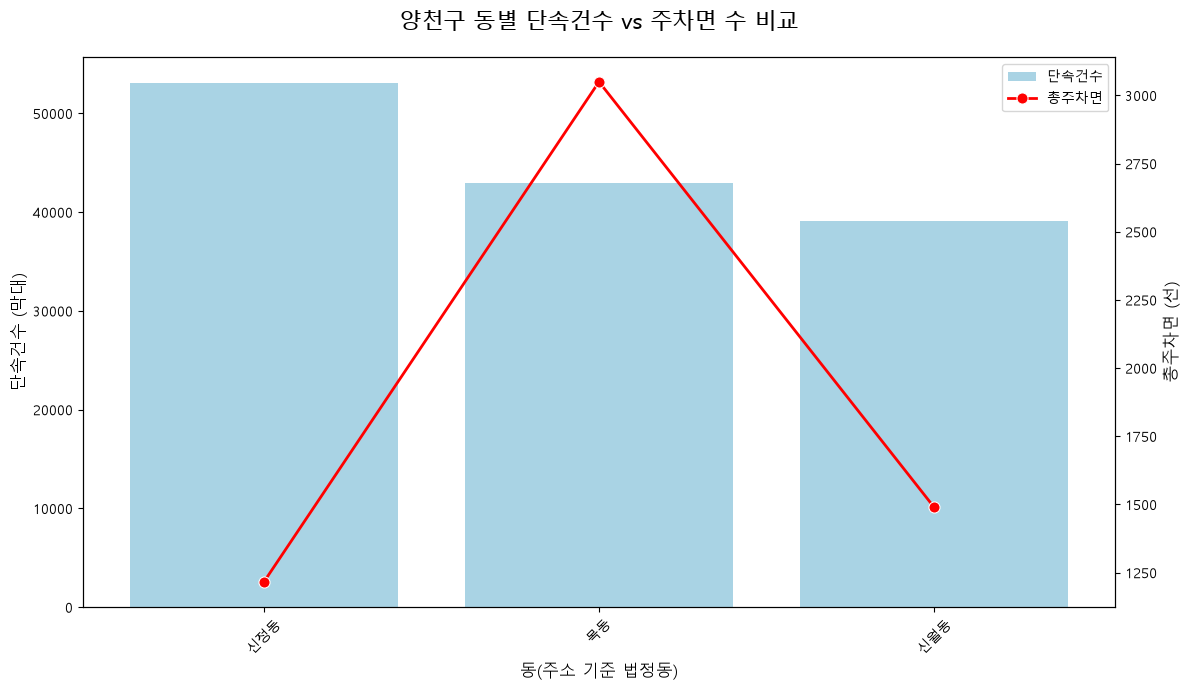

In [180]:
yangcheon_crackdown_counts = yangcheon_top_dong.reset_index()
yangcheon_crackdown_counts.columns = ['주소_동', '단속건수']

yangcheon_parking_supply_df = yangcheon_parking_supply.reset_index()
yangcheon_parking_supply_df.columns = ['주소_동', '총주차면']

yangcheon_merged = pd.merge(yangcheon_crackdown_counts, yangcheon_parking_supply_df, on='주소_동', how='inner')

plt.figure(figsize=(12, 7))

ax1 = plt.gca() 
sns.barplot(x='주소_동', y='단속건수', data=yangcheon_merged, ax=ax1, color='skyblue', label='단속건수', alpha=0.8)

ax2 = ax1.twinx()
sns.lineplot(x='주소_동', y='총주차면', data=yangcheon_merged, ax=ax2, color='red', marker='o', markersize=8, linewidth=2)

ax1.set_title('양천구 동별 단속건수 vs 주차면 수 비교', fontsize=16, pad=20)
ax1.set_xlabel('동(주소 기준 법정동)', fontsize=12)
ax1.set_ylabel('단속건수 (막대)', fontsize=12)
ax2.set_ylabel('총주차면 (선)', fontsize=12)

ax1.tick_params(axis='x', rotation=45)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend([ax1.containers[0], ax2.lines[0]], ['단속건수', '총주차면'], loc='upper right')

plt.tight_layout()
plt.show()

## 3. 결론 및 아이디어 제안
### 분석 결과 요약 및 아이디어 제안
시각화된 분석 결과를 바탕으로 각 지역의 주차 문제에 대한 결론을 도출하고, 이를 해결하기 위한 구체적인 아이디어를 제시합니다.

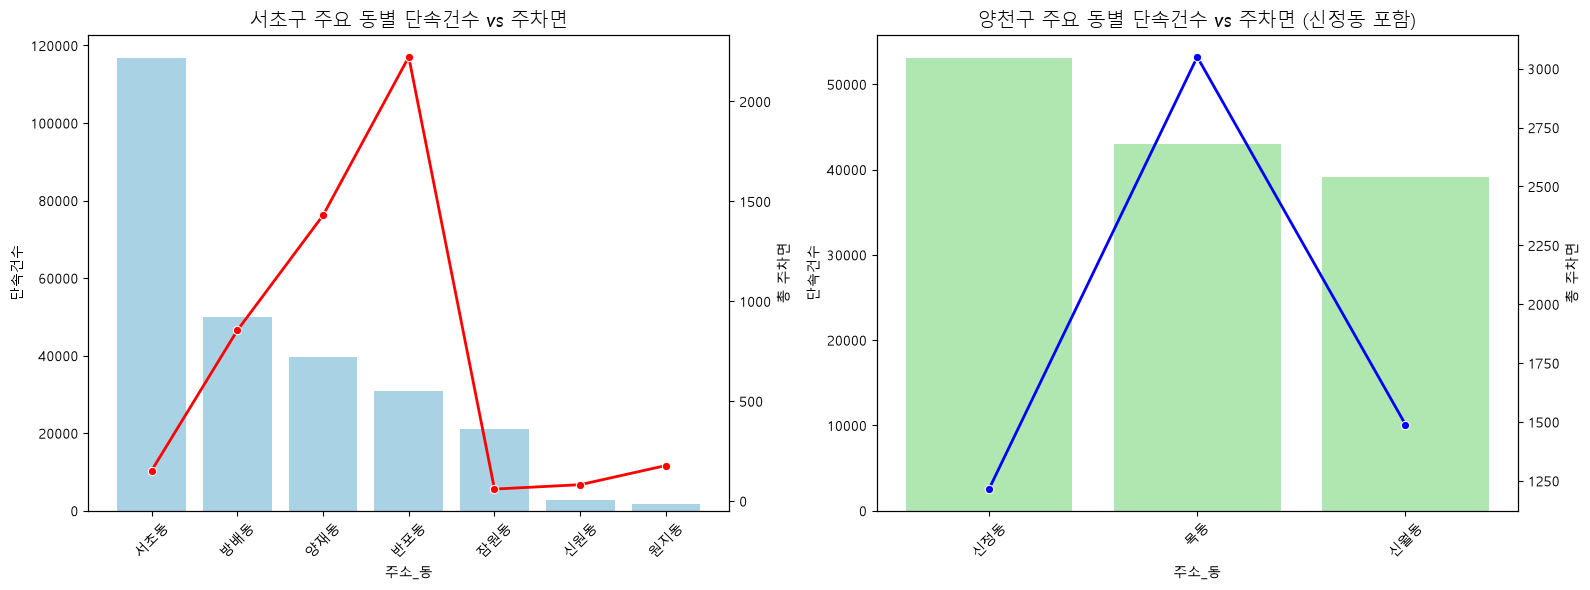

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

seocho_crackdown_cnt = seocho_crackdown['단속동'].value_counts().reset_index()
seocho_crackdown_cnt.columns = ['주소_동', '단속건수']
seocho_parking_cnt = seocho_parking_lot.groupby('주소_동')['총 주차면'].sum().reset_index()
seocho_merged = pd.merge(seocho_crackdown_cnt, seocho_parking_cnt, on='주소_동', how='inner')
seocho_merged['구명'] = '서초구'

yangcheon_crackdown_cnt = yangcheon_crackdown['단속동'].value_counts().reset_index()
yangcheon_crackdown_cnt.columns = ['주소_동', '단속건수']
yangcheon_parking_cnt = yangcheon_parking_lot.groupby('주소_동')['총 주차면'].sum().reset_index()
yangcheon_merged = pd.merge(yangcheon_crackdown_cnt, yangcheon_parking_cnt, on='주소_동', how='inner')
yangcheon_merged['구명'] = '양천구'

fig, axes = plt.subplots(1, 2, figsize=(16, 6))


ax1 = axes[0]
seocho_top = seocho_merged.sort_values(by='단속건수', ascending=False).head(10)
sns.barplot(x='주소_동', y='단속건수', data=seocho_top, ax=ax1, color='skyblue', alpha=0.8)
ax1_twin = ax1.twinx()
sns.lineplot(x='주소_동', y='총 주차면', data=seocho_top, ax=ax1_twin, color='red', marker='o', linewidth=2)
ax1.set_title('서초구 주요 동별 단속건수 vs 주차면', fontsize=14)
ax1.set_xticklabels(seocho_top['주소_동'], rotation=45)
ax1.set_ylabel('단속건수')
ax1_twin.set_ylabel('총 주차면')

ax2 = axes[1]
yangcheon_top = yangcheon_merged.sort_values(by='단속건수', ascending=False).head(10)
sns.barplot(x='주소_동', y='단속건수', data=yangcheon_top, ax=ax2, color='lightgreen', alpha=0.8)
ax2_twin = ax2.twinx()
sns.lineplot(x='주소_동', y='총 주차면', data=yangcheon_top, ax=ax2_twin, color='blue', marker='o', linewidth=2)
ax2.set_title('양천구 주요 동별 단속건수 vs 주차면 (신정동 포함)', fontsize=14)
ax2.set_xticklabels(yangcheon_top['주소_동'], rotation=45)
ax2.set_ylabel('단속건수')
ax2_twin.set_ylabel('총 주차면')

plt.tight_layout()
plt.show()

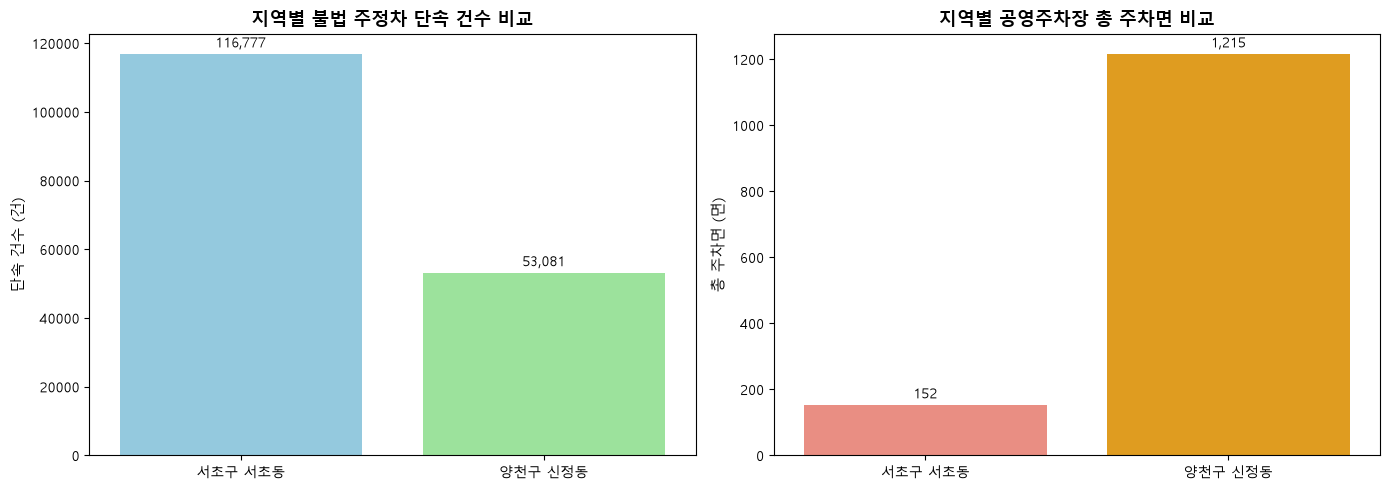

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. 데이터 준비 (서초동 vs 신정동)
seocho_dong_cnt = seocho_crackdown[seocho_crackdown['단속동'] == '서초동'].shape[0]
seocho_dong_park = seocho_parking_lot[seocho_parking_lot['주소_동'] == '서초동']['총 주차면'].sum()

shinjung_dong_cnt = yangcheon_crackdown[yangcheon_crackdown['단속동'] == '신정동'].shape[0]
shinjung_dong_park = yangcheon_parking_lot[yangcheon_parking_lot['주소_동'] == '신정동']['총 주차면'].sum()

compare_df = pd.DataFrame({
    '지역': ['서초구 서초동', '양천구 신정동'],
    '단속건수': [seocho_dong_cnt, shinjung_dong_cnt],
    '총주차면': [seocho_dong_park, shinjung_dong_park]
})

# 2. 1행 2열 서브플롯으로 분리하여 가독성 극대화
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# [왼쪽] 불법 주정차 단속 건수 비교
sns.barplot(x='지역', y='단속건수', data=compare_df, ax=axes[0], palette=['skyblue', 'lightgreen'])
axes[0].set_title('지역별 불법 주정차 단속 건수 비교', fontsize=13, fontweight='bold')
axes[0].set_ylabel('단속 건수 (건)', fontsize=11)
axes[0].set_xlabel('')
# 막대 위 수치 표시
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

# [오른쪽] 공영주차장 총 주차면 비교
sns.barplot(x='지역', y='총주차면', data=compare_df, ax=axes[1], palette=['salmon', 'orange'])
axes[1].set_title('지역별 공영주차장 총 주차면 비교', fontsize=13, fontweight='bold')
axes[1].set_ylabel('총 주차면 (면)', fontsize=11)
axes[1].set_xlabel('')
# 막대 위 수치 표시
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

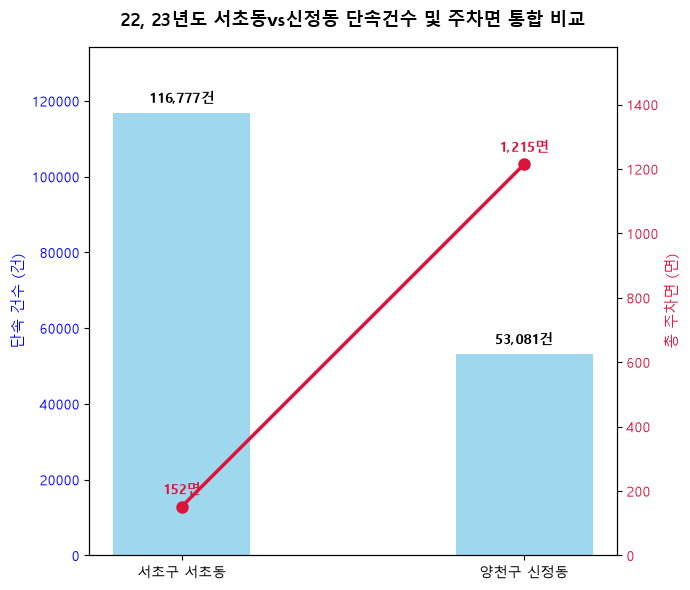

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. 데이터 준비 (서초동 vs 신정동)
seocho_dong_cnt = seocho_crackdown[seocho_crackdown['단속동'] == '서초동'].shape[0]
seocho_dong_park = seocho_parking_lot[seocho_parking_lot['주소_동'] == '서초동']['총 주차면'].sum()

shinjung_dong_cnt = yangcheon_crackdown[yangcheon_crackdown['단속동'] == '신정동'].shape[0]
shinjung_dong_park = yangcheon_parking_lot[yangcheon_parking_lot['주소_동'] == '신정동']['총 주차면'].sum()

compare_df = pd.DataFrame({
    '지역': ['서초구 서초동', '양천구 신정동'],
    '단속건수': [seocho_dong_cnt, shinjung_dong_cnt],
    '총주차면': [seocho_dong_park, shinjung_dong_park]
})

# 2. 하나의 통합 그래프 생성 (슬림한 비율 적용)
fig, ax1 = plt.subplots(figsize=(7, 6))

# [왼쪽 축] 단속건수 (막대 그래프)
color = 'skyblue'
ax1.bar(compare_df['지역'], compare_df['단속건수'], color=color, alpha=0.8, width=0.4, label='단속건수')
ax1.set_ylabel('단속 건수 (건)', fontsize=11, color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_title('22, 23년도 서초동vs신정동 단속건수 및 주차면 통합 비교', fontsize=13, fontweight='bold', pad=15)

# 막대 상단에 수치 표시
for i, v in enumerate(compare_df['단속건수']):
    ax1.text(i, v + 2000, f"{v:,}건", ha='center', va='bottom', fontsize=10, fontweight='bold')

# [오른쪽 축] 총주차면 (꺾은선 그래프)
ax2 = ax1.twinx()
color = 'crimson'
ax2.plot(compare_df['지역'], compare_df['총주차면'], color=color, marker='o', markersize=8, linewidth=2.5, label='총주차면')
ax2.set_ylabel('총 주차면 (면)', fontsize=11, color='crimson')
ax2.tick_params(axis='y', labelcolor='crimson')

# 꺾은선 상단에 수치 표시
for i, v in enumerate(compare_df['총주차면']):
    ax2.text(i, v + 30, f"{v:,}면", ha='center', va='bottom', fontsize=10, fontweight='bold', color='crimson')

# y축 범례 및 레이아웃 정리
ax1.set_ylim(0, max(compare_df['단속건수']) * 1.15)
ax2.set_ylim(0, max(compare_df['총주차면']) * 1.3)
ax1.set_xlabel('')

plt.tight_layout()
plt.show()

In [ ]:
# 데이터 전처리
# 1. 서초구 : 법정동 기준으로 통합 (행정동 기준과 법정동 기준을 결합하여 정확도 상승)
# 2. 양천구 : 법정동 기준 통합시 분석단위가 축소되어 세부 단위 유지하고 양천구, 시민신고들을 필터링
# 하지만 분석단위 유지를 하더라도 각각 법정동의 데이터값이 의미가 적다고 판단하여 양천구 또한 법정동 필터링 진행

# 연관 분석 
# 주차면이 많을수록 단속 건수가 줄어드는 것은 사실, 주차 인프라가 좋지만 단속 건수가 많은 지역도 존재

# 의문점
# 주차공간이 많음에도 단속건수가 줄어들지 않는 것인지

# 아이디어
# 서초구, 양천구 시간별 구간단속 그래프를 보면 3-4시에 집중된 모습 즉 학생들이 하교 할시간에 학원차, 또는 학부모의 차가
# 아닌지에 관해 생각해볼 필요가 있음 (검색결과 양천구는 교육특구 지역, 서초구는 강남 8학군 지역 = 학생들이 많다는 것은 사실이지만
# 실제로 이 때문에 단속건수가 많은지는 확인필요) 

# +서초구는 서울중앙지방법원과 서울중앙지검 유동인구 많음, 상업·업무 시설 존재



1.데이터 통합을 위해 서초구 24년도 제외
2.단속 건수 상위 10개 지역
3.주차면당 단속건수 그래프화

---

In [57]:
# 데이터 분석 및 시각화를 위한 라이브러리들을 임포트합니다.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import warnings
from datetime import datetime
import os
import glob
import matplotlib.font_manager as fm
import subprocess

# 폰트 설정
plt.rc('font', family='Malgun Gothic')

# 경고 제거
import warnings
warnings.filterwarnings(action='ignore')


## 분석데이터를 추가해서, 추가적인 질문에 대한 분석을 해 봅니다.
### 2일차 추가 데이터(업체 현황정보, 생활인구)를 활용하여, 데이터 연관성을 분석해 봅니다.

### 1. 데이터 전처리 (1)

추가된 데이터에 대한 전처리(결측치, 이상치 처리)를 수행해 봅니다.
- 사업체 현황 데이터를 불러옵니다.
    - `사업체현황(산업대분류별_동별).csv`
    - 해당 파일은 UTF-8 형식이므로 `encoding='utf8'` 옵션을 사용합니다.

- 분석에 필요한 형태로 데이터를 정리합니다.
    - `Unnamed: 8`은 값이 없는 불필요한 열이므로 제거합니다.
    - `항목`, `단위` 열은 이번 분석에 사용하지 않으므로 제거합니다.
    - `합계`가 포함된 행은 전체 또는 상위 범위의 집계값이므로,
      동·산업별 데이터를 다시 집계할 때 중복될 수 있어 제외합니다.
    - `-` 값은 숫자로 사용할 수 없는 값이므로
      3개년 비교 및 숫자형 변환을 위해 제외합니다.
    - `구분별`에는 여러 통계 항목이 포함되어 있으므로
      이번 분석에서 사용할 `종사자수`인 행만 선택합니다.
    - `2021 년`, `2022 년`, `2023 년`의 결측값을 제거하고
      숫자형 데이터로 변환합니다.

In [103]:
import pandas as pd
company = pd.read_csv("사업체현황(산업대분류별_동별).csv", encoding = "utf-8")


company = company.drop(columns=['Unnamed: 8', '항목', '단위'], errors = "ignore")
company = company[~company['동별'].str.contains('합계', na=False)]

years = ['2021 년', '2022 년', '2023 년']
for year in years:
    company[year] = pd.to_numeric(company[year].astype(str).str.replace('-', ''), errors='coerce')

company = company.dropna(subset=years)

### 1. 데이터 전처리 (2)
- 행정동코드 매핑 데이터를 불러옵니다.
    - `행정동코드_매핑정보_20241218.xlsx`
    - 파일에는 `행정동코드`, `유입지코드` 2개의 시트가 있으며,
      이번 분석에서는 `행정동코드` 시트를 사용합니다.

- 행정동코드 데이터를 분석에 사용할 형태로 정리합니다.
    - 첫 번째 데이터 행에는 `H_SDNG_CD`, `H_DNG_CD` 등
      컬럼에 대한 영문 코드명이 들어 있으므로 제거합니다.
    - 생활인구 데이터의 `행정동코드`와 연결할 때는
      `행자부행정동코드`를 기준으로 사용합니다.
    - 이번 병합에서 사용하지 않는 `통계청행정동코드`는 제거합니다.
    - 병합할 두 코드의 자료형을 맞추기 위해
      `행자부행정동코드`를 정수형으로 변환합니다.
- 만약 '행정동코드' 시트를 직접 선택하려면 데이터를 불러올 때, 다음과 같은 옵션을 추가합니다.
```python
    area_code_map = pd.read_excel('행정동코드_매핑정보_20241218.xlsx', sheet_name='행정동코드')
```

In [24]:
code_map = pd.read_excel("행정동코드_매핑정보_20241218.xlsx", sheet_name="행정동코드")

code_map = code_map.iloc[1:].reset_index(drop=True)

code_map = code_map.drop(columns=["통계청행정동코드"], errors="ignore")

code_map["행자부행정동코드"] = code_map["행자부행정동코드"].astype(int)

### 1. 데이터 전처리 (3)
- 서울 생활인구(내국인) 데이터를 불러옵니다.
    - `집계구 단위 서울 생활인구(내국인).csv`
- 분석에 사용하지 않는 `기준일ID`, `집계구코드` 컬럼을 제거합니다.
- 생활인구 데이터에 지역명을 추가합니다.
    - 생활인구 데이터의 `행정동코드`를
      행정동코드 매핑정보의 `행자부행정동코드`와 병합합니다.
    - 병합을 통해 `시도명`, `시군구명`, `행정동명` 정보를 추가합니다.
    - 생활인구 데이터를 기준으로 유지할 수 있도록 `left join`을 사용합니다.
- 병합 후 지역정보가 정상적으로 추가되었는지 매핑 성공/실패 건수를 확인합니다.
- **집계구 단위 서울 생활인구(내국인).csv**의 `행정동코드`를 **행정동코드_매핑정보_20241218.xlsx**의 `행자부행정동코드`와 병합하여 시도명, 시군구명, 행정동명을 추가합니다.

In [101]:
people = pd.read_csv("집계구 단위 서울 생활인구(내국인).csv", encoding = "cp949")
people = people.drop(columns= [ "기준일ID", "집계구코드" ], errors = "ignore")

code_map["행자부행정동코드"] = code_map["행자부행정동코드"].astype(int)
people["행정동코드"] = people["행정동코드"].astype(int)

people_code = pd.merge(
    people,
    code_map[["행자부행정동코드", "시도명", "시군구명", "행정동명"]],
    left_on="행정동코드",
    right_on="행자부행정동코드",
    how="left",
)

### 2. 데이터 분석 및 시각화 (1)

추가된 데이터에 대한 탐색적 데이터 분석을 수행해 봅니다. 1일차의 제안 아이디어에 대한 개선점이 될 수 있는지 확인해 봅니다.

  - 신정동(양천구)과 잠원동(서초구)의 주차면수 부족 원인 파악을 위해, 신정동과 잠원동 소재의 사업체 현황을 확인해 봅니다.
      - 1일차에서의 신정동과 잠원동의 주차면수 부족 원인 파악을 위해, 신정동과 잠원동 소재의 사업체 현황 확인
      - 예시 가설 : 3개년 간 해당 지역에 급격히 성장한 산업이 있었나? 

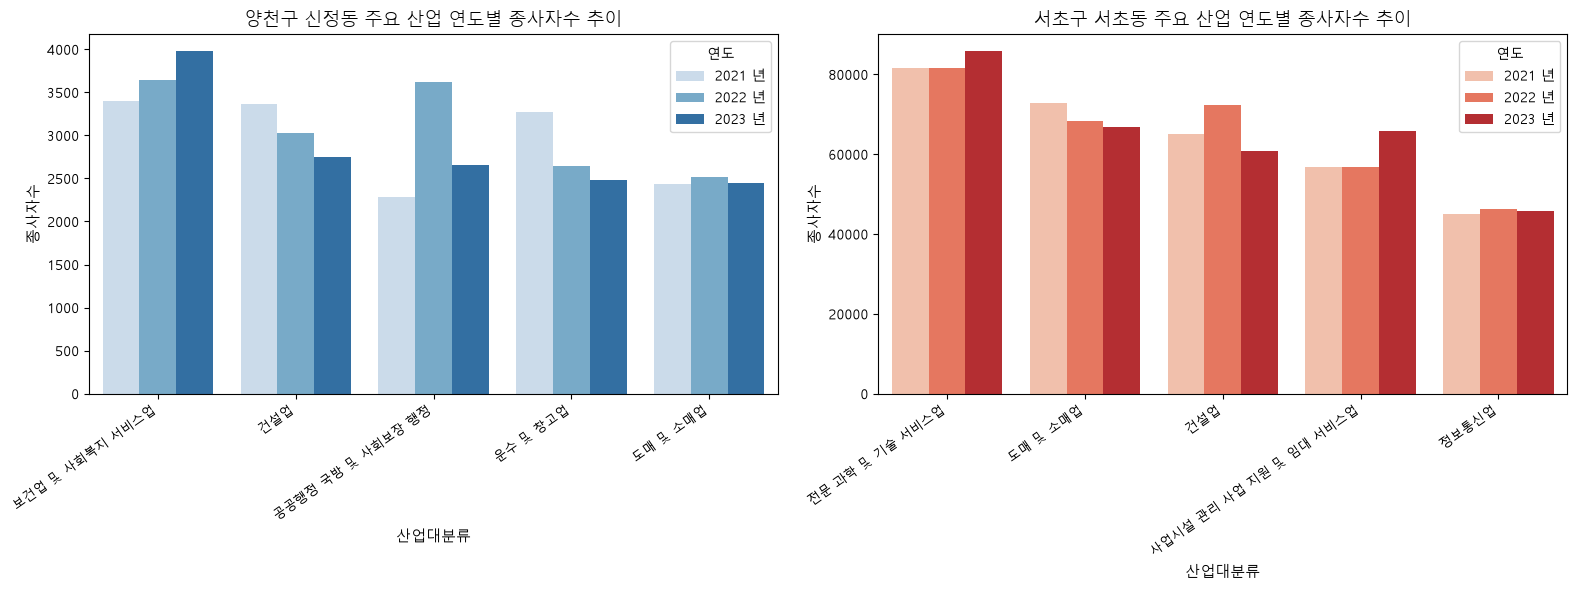

In [77]:
target_company = company[
    (company["동별"].str.contains("신정|서초", na=False))
    & (company["산업대분류별"] != "합계")
].copy()

years = ["2021 년", "2022 년", "2023 년"]
for y in years:
  target_company[y] = (
      target_company[y]
      .astype(str)
      .str.replace(",", "")
      .str.replace("-", "0")
      .str.strip()
  )
  target_company[y] = pd.to_numeric(target_company[y], errors="coerce").fillna(0)

shinjung = (
    target_company[target_company["동별"].str.contains("신정")]
    .assign(평균=lambda x: x[years].mean(axis=1))
    .nlargest(5, "평균")
)
seocho = (
    target_company[target_company["동별"].str.contains("서초")]
    .assign(평균=lambda x: x[years].mean(axis=1))
    .nlargest(5, "평균")
)

combined_top = pd.concat([shinjung, seocho])
melted_df = combined_top.melt(
    id_vars=["동별", "산업대분류별"],
    value_vars=years,
    var_name="연도",
    value_name="종사자수",
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 신정동 그래프
sns.barplot(
    data=melted_df[melted_df["동별"].str.contains("신정")],
    x="산업대분류별",
    y="종사자수",
    hue="연도",
    ax=axes[0],
    palette="Blues",
)
axes[0].set_title("양천구 신정동 주요 산업 연도별 종사자수 추이", fontsize=13)
axes[0].set_xlabel("산업대분류", fontsize=11)
axes[0].set_ylabel("종사자수", fontsize=11)
axes[0].set_xticks(axes[0].get_xticks())
axes[0].set_xticklabels(
    axes[0].get_xticklabels(), rotation=35, ha="right", fontsize=9
)
axes[0].legend(title="연도")

# 서초동 그래프
sns.barplot(
    data=melted_df[melted_df["동별"].str.contains("서초")],
    x="산업대분류별",
    y="종사자수",
    hue="연도",
    ax=axes[1],
    palette="Reds",
)
axes[1].set_title("서초구 서초동 주요 산업 연도별 종사자수 추이", fontsize=13)
axes[1].set_xlabel("산업대분류", fontsize=11)
axes[1].set_ylabel("종사자수", fontsize=11)
axes[1].set_xticks(axes[1].get_xticks())
axes[1].set_xticklabels(
    axes[1].get_xticklabels(), rotation=35, ha="right", fontsize=9
)
axes[1].legend(title="연도")

plt.tight_layout()
plt.show()

### 2. 데이터 분석 및 시각화 (2)

  - 두 지역에서의 시간대 및 연령대별 생활반응 분석을 통해 연관 관계를 도출합니다.
      - 예시 : 행정동명이 잠원동인 데이터의 `시간대구분` 값과 `총생활인구수` 값을 가져와서 잠원동의 시간대 별 생활 인구 수 그래프를 작성

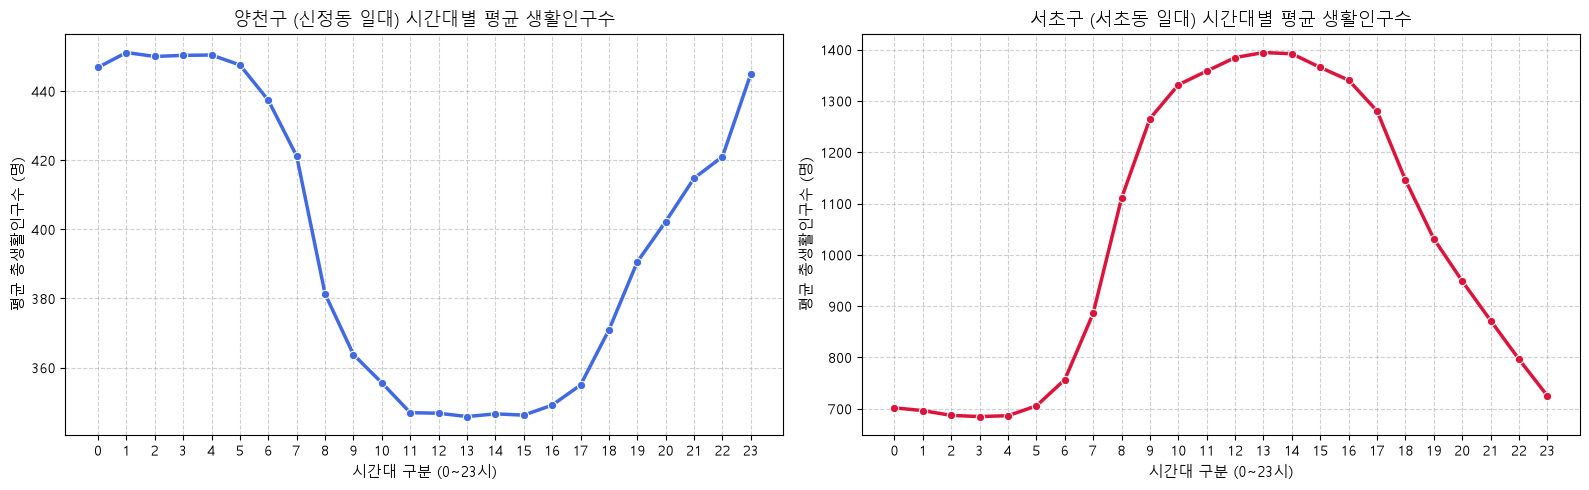

In [88]:
# 1. '신정' 또는 '서초'가 포함된 모든 행정동(신정1~4동, 서초1~4동 등) 필터링
target_people = people_code[
    people_code["행정동명"].str.contains("신정[1-4]동|서초[1-4]동", regex=True, na=False)
].copy()

# 2. '총생활인구수' 컬럼의 쉼표, 공백 제거 후 안전한 숫자로 변환
target_people["총생활인구수"] = (
    target_people["총생활인구수"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.strip()
)
target_people["총생활인구수"] = pd.to_numeric(
    target_people["총생활인구수"], errors="coerce"
)

# 3. 구 단위(서초구 vs 양천구) 기준으로 시간대별 평균 계산
hourly_people = (
    target_people.groupby(["시군구명", "시간대구분"])["총생활인구수"]
    .mean()
    .reset_index()
    .dropna()
)

# 4. 좌우 비교 시각화 (서초구 vs 양천구 전체 하위 동 통합 비교)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 양천구 그래프
sns.lineplot(
    data=hourly_people[hourly_people["시군구명"] == "양천구"],
    x="시간대구분",
    y="총생활인구수",
    marker="o",
    linewidth=2.5,
    color="royalblue",
    ax=axes[0],
)
axes[0].set_title("양천구 (신정동 일대) 시간대별 평균 생활인구수", fontsize=13)
axes[0].set_xlabel("시간대 구분 (0~23시)", fontsize=11)
axes[0].set_ylabel("평균 총생활인구수 (명)", fontsize=11)
axes[0].set_xticks(range(0, 24))
axes[0].grid(True, linestyle="--", alpha=0.6)

# 서초구 그래프
sns.lineplot(
    data=hourly_people[hourly_people["시군구명"] == "서초구"],
    x="시간대구분",
    y="총생활인구수",
    marker="o",
    linewidth=2.5,
    color="crimson",
    ax=axes[1],
)
axes[1].set_title("서초구 (서초동 일대) 시간대별 평균 생활인구수", fontsize=13)
axes[1].set_xlabel("시간대 구분 (0~23시)", fontsize=11)
axes[1].set_ylabel("평균 총생활인구수 (명)", fontsize=11)
axes[1].set_xticks(range(0, 24))
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

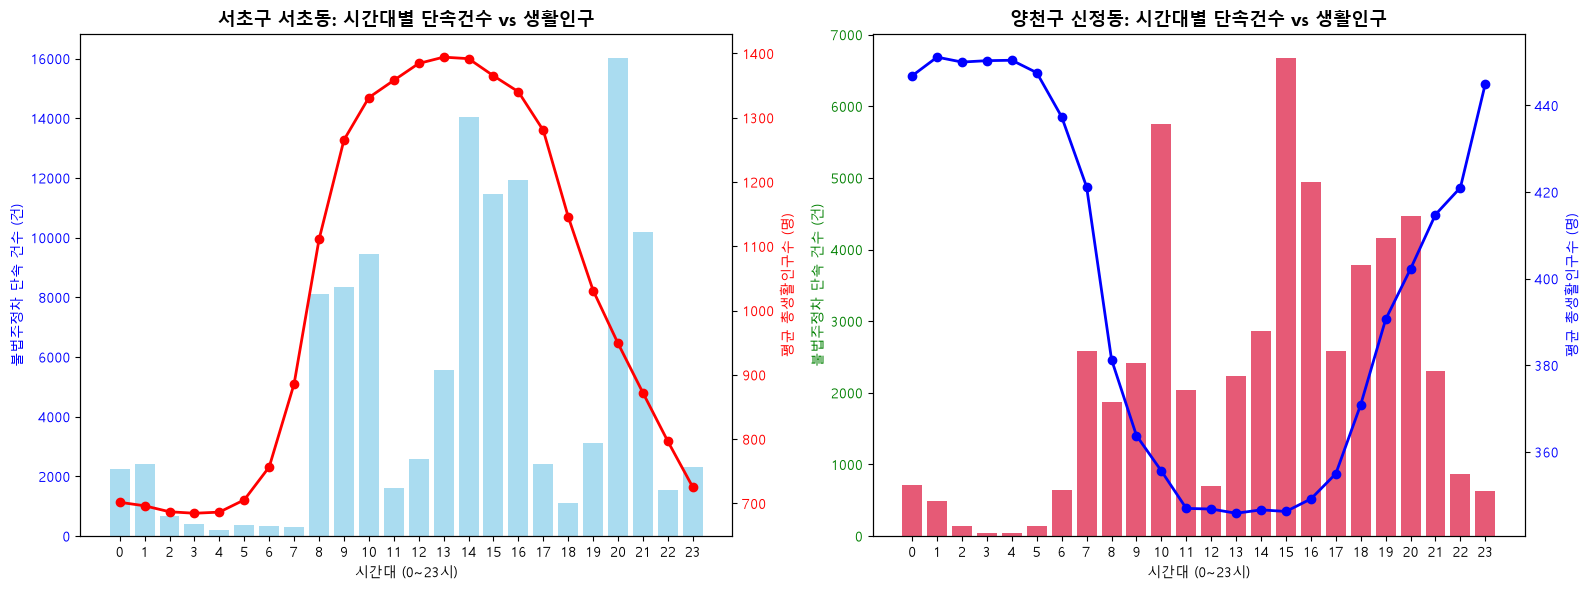

In [107]:
seocho_crackdown['단속동_정제'] = seocho_crackdown['단속동'].str.strip()
seocho_hourly_crack = (
    seocho_crackdown[seocho_crackdown['단속동_정제'] == '서초동']['단속시간']
    .value_counts()
    .sort_index()
)

shinjung_crackdown['단속동_정제'] = shinjung_crackdown['단속동'].str.strip()
shinjung_hourly_crack = (
    shinjung_crackdown[shinjung_crackdown['단속동_정제'] == '신정동']['단속시간']
    .value_counts()
    .sort_index()
)

# 2. 서초동, 신정동 각각의 시간대별 평균 생활인구수 집계
seocho_pop = (
    people_code[people_code['행정동명'].str.contains('서초[1-4]동', na=False)]
    .groupby('시간대구분')['총생활인구수']
    .mean()
    .sort_index()
)
shinjung_pop = (
    people_code[people_code['행정동명'].str.contains('신정[1-4]동', na=False)]
    .groupby('시간대구분')['총생활인구수']
    .mean()
    .sort_index()
)

# 3. 서브플롯으로 서초구(서초동)와 양천구(신정동) 비교 시각화
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- [왼쪽] 서초구 서초동: 단속건수(막대) vs 생활인구(선) ---
ax1 = axes[0]
ax1.bar(
    seocho_hourly_crack.index,
    seocho_hourly_crack.values,
    color='skyblue',
    alpha=0.7,
    label='단속건수',
)
ax1.set_ylabel('불법주정차 단속 건수 (건)', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

ax1_twin = ax1.twinx()
ax1_twin.plot(
    seocho_pop.index,
    seocho_pop.values,
    color='red',
    marker='o',
    linewidth=2,
    label='생활인구수',
)
ax1_twin.set_ylabel('평균 총생활인구수 (명)', color='red')
ax1_twin.tick_params(axis='y', labelcolor='red')

ax1.set_title(
    '서초구 서초동: 시간대별 단속건수 vs 생활인구',
    fontsize=13,
    fontweight='bold',
)
ax1.set_xlabel('시간대 (0~23시)')
ax1.set_xticks(range(0, 24))

# --- [오른쪽] 양천구 신정동: 단속건수(막대) vs 생활인구(선) ---
ax2 = axes[1]
ax2.bar(
    shinjung_hourly_crack.index,
    shinjung_hourly_crack.values,
    color='crimson',
    alpha=0.7,
    label='단속건수',
)
ax2.set_ylabel('불법주정차 단속 건수 (건)', color='green')
ax2.tick_params(axis='y', labelcolor='green')

ax2_twin = ax2.twinx()
ax2_twin.plot(
    shinjung_pop.index,
    shinjung_pop.values,
    color='blue',
    marker='o',
    linewidth=2,
    label='생활인구수',
)
ax2_twin.set_ylabel('평균 총생활인구수 (명)', color='blue')
ax2_twin.tick_params(axis='y', labelcolor='blue')

ax2.set_title(
    '양천구 신정동: 시간대별 단속건수 vs 생활인구',
    fontsize=13,
    fontweight='bold',
)
ax2.set_xlabel('시간대 (0~23시)')
ax2.set_xticks(range(0, 24))

plt.tight_layout()
plt.show()

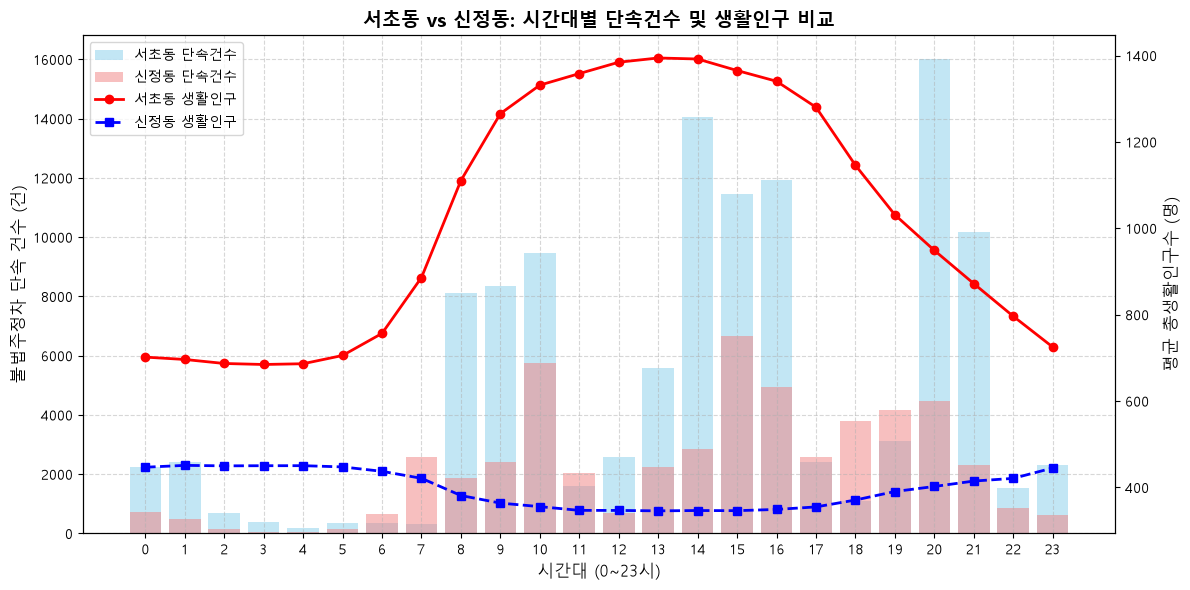

['동별', '산업대분류별', '구분별', '2021 년', '2022 년', '2023 년']


In [110]:
# 서초동과 신정동을 하나의 비교 그래프로 통합 시각화
fig, ax1 = plt.subplots(figsize=(12, 6))

# 1. 서초동 데이터 (생활인구 & 단속건수)
ax1.bar(
    seocho_hourly_crack.index,
    seocho_hourly_crack.values,
    color='skyblue',
    alpha=0.5,
    label='서초동 단속건수',
)
ax1_twin = ax1.twinx()
ax1_twin.plot(
    seocho_pop.index,
    seocho_pop.values,
    color='red',
    marker='o',
    linewidth=2,
    label='서초동 생활인구',
)

# 2. 신정동 데이터 (생활인구 & 단속건수)
ax1.bar(
    shinjung_hourly_crack.index,
    shinjung_hourly_crack.values,
    color='lightcoral',
    alpha=0.5,
    label='신정동 단속건수',
)
ax1_twin.plot(
    shinjung_pop.index,
    shinjung_pop.values,
    color='blue',
    marker='s',
    linewidth=2,
    linestyle='--',
    label='신정동 생활인구',
)

ax1.set_title(
    '서초동 vs 신정동: 시간대별 단속건수 및 생활인구 비교',
    fontsize=14,
    fontweight='bold',
)
ax1.set_xlabel('시간대 (0~23시)', fontsize=12)
ax1.set_ylabel('불법주정차 단속 건수 (건)', fontsize=12)
ax1_twin.set_ylabel('평균 총생활인구수 (명)', fontsize=12)
ax1.set_xticks(range(0, 24))

# 범례 통합 표시
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax1_twin.get_legend_handles_labels()
ax1.legend(
    lines_1 + lines_2, labels_1 + labels_2, loc='upper left', fontsize=10
)

ax1.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print(company.columns.tolist())

### 3. 인사이트 도출

데이터 분석 근거에 대한 결론을 도출하고 제안에 맞는지 확인 해 봅니다.
제안 근거 및 설득력 있는 시각화를 위해서 어떤 방식이 좋은지 생각해 봅니다.


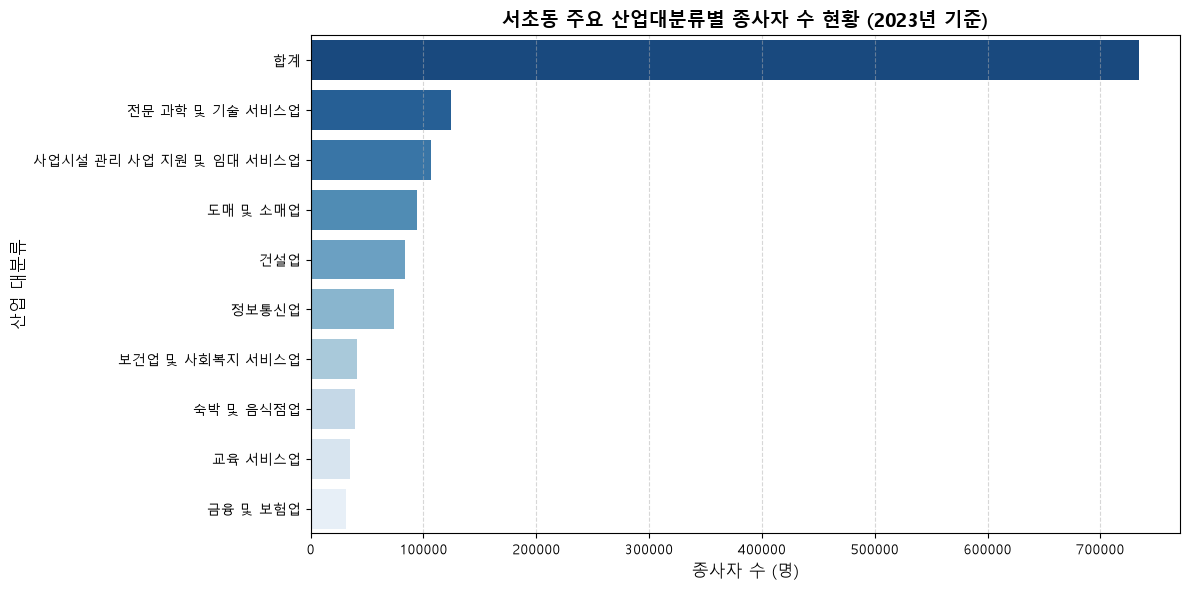

In [111]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. 서초동(서초1~4동)에 해당하는 사업체 데이터 필터링 (종사자수 기준)
seocho_comp = company[
    (company['동별'].str.contains('서초', na=False))
    & (company['구분별'].str.contains('종사자수', na=False))
].copy()

# 2. 산업대분류별 종사자수 합계 집계 (2023년 기준 정렬)
seocho_comp_grouped = (
    seocho_comp.groupby('산업대분류별')['2023 년']
    .sum()
    .reset_index()
    .sort_values(by='2023 년', ascending=False)
)

# 3. 시각화 (서초동 산업별 종사자 현황 바차트)
plt.figure(figsize=(12, 6))
sns.barplot(
    data=seocho_comp_grouped.head(10),
    x='2023 년',
    y='산업대분류별',  # 컬럼명을 올바르게 수정
    palette='Blues_r',
)

plt.title(
    '서초동 주요 산업대분류별 종사자 수 현황 (2023년 기준)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('종사자 수 (명)', fontsize=12)
plt.ylabel('산업 대분류', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

여기에 의견을 적어 봅니다.




서초동

낮 시간 인구 많음: 업무 및 상업 중심지
+ 단속건수 1위 에비뉴 같은 경우 , 대단지 아파트 및 인근 상가로 인해 혼잡 구간

그래프 경향: 08시부터 16시까지 단속 건수 및 생활인구 동반 증가

시사점: 주간에 단속 건수와 생활인구가 동반 상승하므로, 서초동에 주차장을 신설하는 것이 타당함





신정동

밤부터 새벽 시간 인구 많음: 주거 밀집 지역

그래프 경향: 23시부터 05시까지 생활인구는 증가하나 단속 건수는 오히려 감소

시사점: 생활인구는 많지만 새벽 시간 행정 부재로 인해 단속 건수가 적으므로, 신설할 타당한 근거가 다소 불충분함

# **<2일차 조별과제>**

## 분석 결과와 아이디어를 검토하고, 추가적인 데이터 분석 방법을 찾아서 시각화 해 봅니다.

개별로 분석한 결과를 조/팀별 공유 및 토론을 통해서 대표적인 데이터 분석 방법 및 시각화 방법을 찾고, 구현해 봅니다. 

### 3. 최종 제안 아이디어 정리

프로젝트 목적에 맞는 결론을 정리하여, 발표자료에 사용할 내용을 정리해 봅니다.


여기에 의견을 적어 봅니다.

